# What should adaptive therapy optimise? Experiments E0–E10

One environment (Strobl 2021's two-population Lotka–Volterra model, in Gallagher 2023's form), four published objectives ported into it, one RL algorithm, and **every agent scored on every metric**. The cells follow the Phase 2 experiment matrix in order, E0 → E10.

PPO checkpoints are cached under `results/agents/`, so re-running only trains what is missing. Figures go to `figures/`. Every design choice and its alternatives are in `decisions.md`; the data flow is in `model_flow.md`.

| Objective | Ported from | Reward per 7-day decision (γ = 0.999 per step) |
|---|---|---|
| **R1** survival + holiday | Gallagher 2023, Table 1 (verbatim) | +0.1 per step alive, +0.05 if no drug, −0.1 at progression, +5 at 30 years |
| **R2** dose + time | Gluzman 2020 (negated) | −0.1·(D + σ), σ = 0.01; progression −101 (= worst step / (1−γ)); +5 at 30 years |
| **R3** coexistence | Giles & Newton 2026 | +0.1 if H ≥ 0.9995·H_max, −0.1 if H < 0.05·H_max, else 0; progression −100 |
| **R4** durability | Yao 2024 (per-step port, on the resistant *fraction*) | +0.1 − 0.1·f₁₈₀, where f₁₈₀ is the resistant fraction the tumour would have after a simulated 180-day treatment holiday; −0.1 at progression; +5 at 30 years |

**State the network sees:** N/N₀, S/K, R/K and log₁₀(R/N), i.e. full composition (the oracle case). **Action:** treat at full dose or withhold, held for 7 days. Progression (N ≥ 1.2 N₀) is checked at every 0.5-day RK4 substep.

In [1]:
import os, sys, json, itertools
from types import SimpleNamespace
sys.path.insert(0, os.path.abspath('src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import Rectangle
from scipy import stats
from scipy.integrate import solve_ivp
from atrl import *

RES, FIG = 'results', 'figures'
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)
with open(f'{RES}/config.json', 'w') as f:
    json.dump(CFG, f, indent=1)
SUMMARY = {}

COL = dict(R1='#2a78d6', R2='#eb6834', R3='#1baf7a', R4='#eda100')   # validated categorical slots 1-4
INK, MUTED, GRID, NAVY = '#2A2A2A', '#898781', '#E1E0D9', '#1B2A4A'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
BLUES.set_bad('#EDEDEA')
POLMAP = ListedColormap(['#EDEDEA', '#256abf'])                       # withhold, treat
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': GRID, 'grid.linewidth': .8, 'axes.edgecolor': '#C3C2B7',
                     'axes.axisbelow': True, 'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
                     'axes.titlesize': 11, 'font.size': 10, 'lines.linewidth': 2, 'figure.dpi': 100,
                     'legend.frameon': False})
pd.set_option('display.precision', 3, 'display.width', 220, 'display.max_columns', 40)


def save(name):
    plt.savefig(f'{FIG}/{name}.png', dpi=160, bbox_inches='tight'); plt.show()


def miqr(x):
    # median [IQR]: medians and spread, never the mean alone (Phase 2, Metrics)
    q = np.nanpercentile(np.asarray(x, float), [25, 50, 75])
    return f'{q[1]:.3g} [{q[0]:.3g}, {q[2]:.3g}]'


def evaluate(pols, patients=(POP,), interval=7, drug='cytotoxic', objs=OBJECTIVES):
    # score {name: policy} on every metric for every patient -> long DataFrame
    rows = []
    for name, pol in pols.items():
        m = rollout(pol, list(patients), interval=interval, drug=drug, objs=objs)
        keys = [k for k in m if k not in ('traj', 'progressed')]
        rows += [dict(policy=name, patient=i, **{k: m[k][i] for k in keys}) for i in range(len(patients))]
    return pd.DataFrame(rows)


def split(df):
    # 'R1|s3' -> obj='R1', seed='s3'
    df = df.copy()
    df['obj'], df['seed'] = df.policy.str.split('|').str[0], df.policy.str.split('|').str[1]
    return df


def score(G, obj, floor, ceil):
    # discounted return rescaled so no treatment = 0 and the VI optimum = 1
    # undefined (nan) when the optimum is no better than no treatment (span below half a step's reward)
    span = ceil[obj] - floor[obj]
    return (G - floor[obj]) / span if span > 0.05 else G * np.nan


def composition(ax, pol, title, interval=1, p=POP):
    m = rollout(pol, [p], interval=interval, record=True, objs=())
    tr = m['traj']
    t, S, R, D = tr['t'], tr['S'][:, 0] / p['N0'], tr['R'][:, 0] / p['N0'], tr['D'][:, 0]
    ax.fill_between(t, 0, S, color=COL['R1'], lw=0, step='post', label='sensitive')
    ax.fill_between(t, S, S + R, color=COL['R2'], lw=0, step='post', label='resistant')
    ax.fill_between(t, 1.31, 1.37, where=D > 0, color=INK, lw=0, step='post', label='drug on')
    ax.axhline(CFG['prog'], color=MUTED, ls=(0, (5, 4)), lw=1)
    ax.set_ylim(0, 1.4); ax.set_xlabel('days'); ax.set_title(f'{title}: TTP {m["TTP"][0]:.0f} d')
    return m

## E0: Is the environment correct?

The target is Gallagher's proof-of-principle patient. Its parameters are not in the preprint PDF (they sit in SI 2). They were taken from `paper_figures/figure_2.ipynb` in `MathOnco/DRL_Personalized_AT`:
- n₀ = 0.75, f_R = 0.001, cost = 0, turnover = 0;
- r_S = r_R = 0.027/day, d_D = 1.5, K = 1.

The paper reports **CT ≈ 450–451 d**, and **AT50 = 662 d** in the Fig 2 text but **672 d** in the Table 2 caption. We check three things:
1. both numbers at several decision cadences;
2. our fixed-step RK4 against an independent `solve_ivp` reference;
3. what goes wrong if progression is checked only at decision points.

In [2]:
def at50_checked_at_decisions(interval):
    # AT50 with progression checked ONLY at decision points - the trap the Phase 2 doc warns about
    p = stack(POP); S, R = p['N0'] * (1 - p['fR']), p['N0'] * p['fR']
    pol, t, saved = ATx(.5), 0.0, CFG['prog']
    pol.reset(1); CFG['prog'] = np.inf
    try:
        while t < CFG['tmax']:
            S, R, _, _ = advance(S, R, pol(S, R, t, p), p, interval); t += interval
            if S[0] + R[0] >= 1.2 * p['N0'][0]:
                return t
    finally:
        CFG['prog'] = saved


e0 = pd.DataFrame([dict(interval_days=iv,
                        CT=rollout(Const(1), [POP], interval=iv, objs=())['TTP'][0],
                        AT50=rollout(ATx(.5), [POP], interval=iv, objs=())['TTP'][0],
                        AT50_checked_only_at_decisions=at50_checked_at_decisions(iv))
                   for iv in (1, 7, 28)]).set_index('interval_days')
e0

,CT,AT50,AT50_checked_only_at_decisions
interval_days,,,
1,451.605,662.762,663.0
7,451.605,673.219,679.0
28,451.605,671.299,672.0


In [3]:
def reference_ttp(policy, p, interval):
    # independent check: scipy solve_ivp (rtol 1e-10) with a progression event
    S, R, t, pb = p['N0'] * (1 - p['fR']), p['N0'] * p['fR'], 0.0, stack(p)
    policy.reset(1)
    while t < CFG['tmax']:
        D = float(policy(np.array([S]), np.array([R]), t, pb)[0])
        ev = lambda _, y: y[0] + y[1] - CFG['prog'] * p['N0']
        ev.terminal, ev.direction = True, 1
        s = solve_ivp(lambda _, y: list(deriv(y[0], y[1], D, p)), (t, t + interval), [S, R],
                      events=ev, rtol=1e-10, atol=1e-12)
        if s.t_events[0].size:
            return s.t_events[0][0]
        S, R = s.y[:, -1]; t += interval


chk = pd.DataFrame({iv: dict(CT_rk4=e0.loc[iv, 'CT'], CT_solve_ivp=reference_ttp(Const(1), POP, iv),
                             AT50_rk4=e0.loc[iv, 'AT50'], AT50_solve_ivp=reference_ttp(ATx(.5), POP, iv))
                    for iv in (1, 7, 28)}).T
p01 = patient(fR=0.01)
print('With the Phase 2 table value f_R = 0.01 instead: CT = %.1f d, AT50 = %.1f d  -> does not reproduce' %
      (rollout(Const(1), [p01], interval=1, objs=())['TTP'][0], rollout(ATx(.5), [p01], interval=1, objs=())['TTP'][0]))
assert abs(e0.loc[1, 'CT'] - 451.6) < 1 and abs(e0.loc[1, 'AT50'] - 662.8) / 662.8 < 0.01
assert (abs(chk.CT_rk4 - chk.CT_solve_ivp) < 0.5).all() and (abs(chk.AT50_rk4 - chk.AT50_solve_ivp) < 0.5).all()
SUMMARY['E0'] = dict(CT=round(e0.loc[1, 'CT'], 1), AT50_daily=round(e0.loc[1, 'AT50'], 1),
                     AT50_weekly=round(e0.loc[7, 'AT50'], 1),
                     AT50_28d_checked_at_decisions=float(e0.loc[28, 'AT50_checked_only_at_decisions']))
print('E0 PASSED')
chk

With the Phase 2 table value f_R = 0.01 instead: CT = 368.7 d, AT50 = 472.8 d  -> does not reproduce
E0 PASSED


,CT_rk4,CT_solve_ivp,AT50_rk4,AT50_solve_ivp
1,451.605,451.605,662.762,662.762
7,451.605,451.605,673.219,673.219
28,451.605,451.605,671.299,671.299


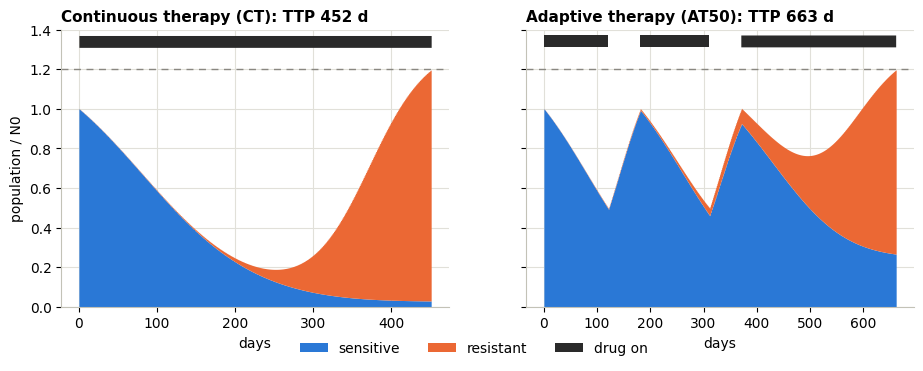

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
composition(axs[0], Const(1), 'Continuous therapy (CT)')
composition(axs[1], ATx(.5), 'Adaptive therapy (AT50)')
axs[0].set_ylabel('population / N0')
fig.legend(*axs[1].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(.5, -.06))
save('E0_ct_vs_at50')

**Reading E0.** CT = 451.6 d matches exactly, and AT50 = 662.8 d (daily decisions) matches the paper's Fig 2 text. The 672 d in Table 2 is reproduced only by a 28-day cadence with progression checked **only at decisions**. That is the implementation trap, which overstates TTP. RK4 at dt = 0.5 d agrees with `solve_ivp` to well under half a day at every cadence. The environment is correct. Everything downstream uses f_R = 0.001, not the 0.01 in the Phase 2 parameter table.

## E1: Where is there room to improve at all?

The full baseline suite runs on the proof-of-principle (PoP) patient at the agents' 7-day cadence. Ma's AT-PSC is a tuned heuristic, so its surveillance threshold N_T and on-window T1 are tuned for this patient. Ma's literal 13-of-30 rule fails here (shown below). We then map the gain of the best AT-x over MTD across Strobl/Gallagher's (cost, turnover) plane, and the headroom that the R1-optimal policy leaves above the best heuristic.

In [5]:
psc = pd.DataFrame([dict(N_T=nt, T1=t1, TTP=rollout(PSC(nt, t1, 28), [POP], objs=())['TTP'][0])
                    for nt in (.5, .6, .7, .8, .9, 1.0, 1.1) for t1 in (7, 14, 21, 28)])
best_psc = psc.loc[psc.TTP.idxmax()]
print(f'tuned AT-PSC: N_T = {best_psc.N_T} N0, treat {best_psc.T1:.0f} of every 28 days -> TTP {best_psc.TTP:.0f} d')
for k, pol in {'IT 30/30 (daily, as Ma)': Intermittent(30, 30), 'AT-PSC 13 of 30, N_T = N0 (daily, as Ma)': PSC(1.0, 13, 30)}.items():
    print(f'{k}: TTP {rollout(pol, [POP], interval=1, objs=())["TTP"][0]:.0f} d')
psc.pivot(index='N_T', columns='T1', values='TTP').round(0)

tuned AT-PSC: N_T = 1.0 N0, treat 28 of every 28 days -> TTP 1135 d
IT 30/30 (daily, as Ma): TTP 175 d
AT-PSC 13 of 30, N_T = N0 (daily, as Ma): TTP 80 d


T1,7,14,21,28
N_T,,,,
0.5,72.0,167.0,639.0,547.0
0.6,72.0,167.0,639.0,614.0
0.7,72.0,167.0,707.0,703.0
0.8,72.0,167.0,754.0,796.0
0.9,72.0,167.0,914.0,919.0
1.0,51.0,83.0,1118.0,1135.0
1.1,51.0,83.0,167.0,83.0


In [6]:
BASE = baselines(7, psc_NT=float(best_psc.N_T), psc_T1=int(best_psc.T1))
e1 = evaluate(BASE).set_index('policy').drop(columns='patient')
BEST_AT = e1.loc[['AT25', 'AT50', 'AT75', 'AT90'], 'TTP'].idxmax()   # best Zhang-style threshold
BEST_H = e1.TTP.idxmax()                                                # best heuristic of any kind
SUMMARY['E1'] = {k: round(float(v), 1) for k, v in e1.TTP.items()}
print('best AT-x:', BEST_AT, '| best heuristic overall (the tuned-heuristic ceiling):', BEST_H)
e1

best AT-x: AT90 | best heuristic overall (the tuned-heuristic ceiling): AT-PSC


,TTP,dose,dose_pct,mean_fR,term_fR,mean_burden,regrow,f_holiday,G_R1,G_R2,G_R3,G_R4
policy,,,,,,,,,,,,
None,40.690,0.000,0.000,0.001,0.001,1.095,0.022,0.001,0.649,-100.502,-100.000,0.399
MTD,451.605,451.605,100.000,0.386,0.976,0.559,0.022,0.976,6.109,-101.095,-95.188,3.694
AT25,587.644,489.644,83.323,0.223,0.763,0.759,0.022,0.763,8.552,-99.742,-93.329,6.121
AT50,673.219,547.219,81.284,0.192,0.752,0.833,0.022,0.752,9.935,-99.355,-92.140,7.303
AT75,798.136,623.136,78.074,0.157,0.667,0.919,0.022,0.667,11.888,-98.695,-91.217,9.004
AT90,932.470,708.470,75.978,0.132,0.608,0.983,0.022,0.608,13.893,-98.047,-90.514,10.753
IT,166.494,84.000,50.452,0.002,0.002,1.052,0.022,0.002,2.720,-99.915,-100.000,2.173
AT-PSC,1135.038,855.038,75.331,0.117,0.609,1.046,0.022,0.609,16.763,-97.315,-88.596,13.168


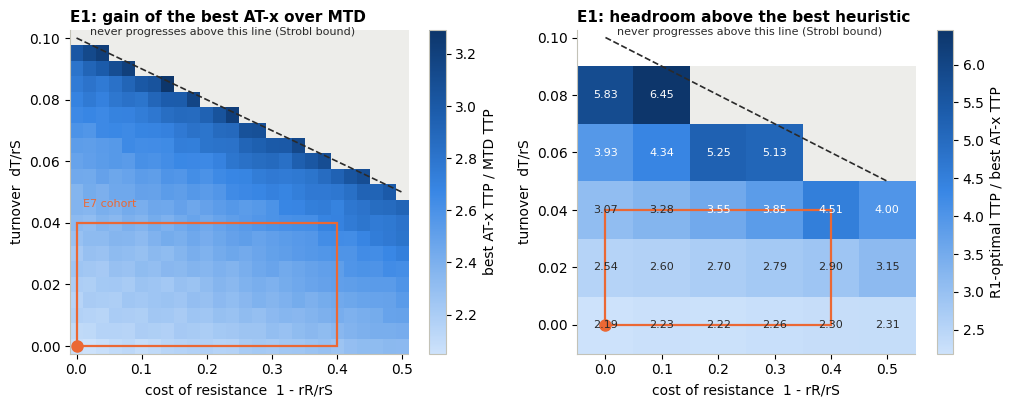

{'gain_range': [2.05, 3.29], 'headroom_range': [2.19, 6.45]}

In [7]:
costs, turns = np.linspace(0, .5, 26), np.linspace(0, .1, 21)
plane = [patient(c, u) for u in turns for c in costs]
ttp = {k: rollout(BASE[k], plane, objs=())['TTP'] for k in ('MTD', 'AT25', 'AT50', 'AT75', 'AT90')}
best_at = np.max([ttp[k] for k in ('AT25', 'AT50', 'AT75', 'AT90')], 0)
gain = np.where(ttp['MTD'] >= CFG['tmax'], np.nan, best_at / ttp['MTD']).reshape(len(turns), len(costs))

cc, tt = np.linspace(0, .5, 6), np.linspace(0, .08, 5)      # R1 optimum on a coarse sub-grid
head = np.full((len(tt), len(cc)), np.nan)
for i, u in enumerate(tt):
    for j, c in enumerate(cc):
        p = patient(c, u)
        b = max(rollout(ATx(x), [p], objs=())['TTP'][0] for x in (.25, .5, .75, .9))
        if b < CFG['tmax']:
            head[i, j] = rollout(Lookahead(solve_vi('R1', p)), [p], objs=())['TTP'][0] / b

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
im = axs[0].imshow(gain, origin='lower', aspect='auto', cmap=BLUES, interpolation='nearest',
                   extent=[costs[0] - .01, costs[-1] + .01, turns[0] - .0025, turns[-1] + .0025])
fig.colorbar(im, ax=axs[0], label='best AT-x TTP / MTD TTP')
axs[0].set_title('E1: gain of the best AT-x over MTD')
dc, du = cc[1] - cc[0], tt[1] - tt[0]
im = axs[1].imshow(head, origin='lower', aspect='auto', cmap=BLUES, interpolation='nearest',
                   extent=[cc[0] - dc / 2, cc[-1] + dc / 2, tt[0] - du / 2, tt[-1] + du / 2])
for i in range(len(tt)):
    for j in range(len(cc)):
        if not np.isnan(head[i, j]):
            axs[1].text(cc[j], tt[i], f'{head[i, j]:.2f}', ha='center', va='center', fontsize=8,
                        color='white' if head[i, j] > np.nanmean(head) else INK)
fig.colorbar(im, ax=axs[1], label='R1-optimal TTP / best AT-x TTP')
axs[1].set_title('E1: headroom above the best heuristic')
x = np.linspace(0, .5, 50)
for ax in axs:
    ax.plot(x, .1 * (1 - x), color=INK, lw=1.2, ls='--')
    ax.text(.02, .1 * (1 - .02) + .003, 'never progresses above this line (Strobl bound)', fontsize=8, color=INK)
    ax.add_patch(Rectangle((0, 0), .4, .04, fill=False, ec=COL['R2'], lw=1.6))
    ax.plot(0, 0, 'o', color=COL['R2'], ms=8, clip_on=False)
    ax.set_xlabel('cost of resistance  1 - rR/rS'); ax.set_ylabel('turnover  dT/rS'); ax.grid(False)
axs[0].set_xlim(-.01, .51); axs[0].set_ylim(-.0025, .1025)
axs[1].set_xlim(cc[0] - dc / 2, cc[-1] + dc / 2); axs[1].set_ylim(tt[0] - du / 2, .1025)
axs[0].text(.01, .045, 'E7 cohort', color=COL['R2'], fontsize=8)
save('E1_cost_turnover')
SUMMARY['E1_heatmap'] = dict(gain_range=[round(float(np.nanmin(gain)), 2), round(float(np.nanmax(gain)), 2)],
                             headroom_range=[round(float(np.nanmin(head)), 2), round(float(np.nanmax(head)), 2)])
SUMMARY['E1_heatmap']

**Reading E1.** On the PoP patient:
- MTD gives 452 d and AT50 673 d. AT-x improves monotonically with x (AT90: 932 d). Withdrawing earlier keeps more sensitive competitors alive.
- Ma's literal AT-PSC (13 of 30 days, 80 d) and fixed intermittent therapy (166 d) both fail here. A schedule that does not respond to burden loses on a fast-progressing patient.
- Tuning AT-PSC drives it to a **full** cycle at N_T = N₀ (1135 d). That is a containment rule, and it is the strongest heuristic.

Across the (cost, turnover) plane, the best AT-x gives 2.0–3.3× MTD's TTP, rising with turnover as Strobl reports. The R1 optimum leaves another **2.2–6.5×** above the best AT-x everywhere. There is a lot of room to improve, and E2 shows where it comes from.

## E2: What is the best achievable, per objective?

This is exact policy iteration on the discretised MDP: 161 linear burden levels × 241 log-spaced resistant fractions, bilinear interpolation, and absorbing progression. The transitions use the same integrator and the same reward code as training. The greedy one-step-lookahead policy is then **simulated in the continuous environment**, and that realised return is each objective's ceiling. Each objective gets its own optimum, which gives a column of ceilings rather than one number.

In [8]:
VI = {o: solve_vi(o, POP) for o in OBJECTIVES}
VIP = {f'VI-{o}': Lookahead(VI[o]) for o in OBJECTIVES}
e2 = evaluate(VIP).set_index('policy').drop(columns='patient')
FLOOR = {o: e1.loc['None', f'G_{o}'] for o in OBJECTIVES}
CEIL = {o: e2.loc[f'VI-{o}', f'G_{o}'] for o in OBJECTIVES}
e2.insert(0, 'V0_grid', [VI[o]['V0'] for o in OBJECTIVES])
e2.insert(1, 'G_own_realised', [CEIL[o] for o in OBJECTIVES])
e2.insert(2, 'PI_iterations', [VI[o]['iters'] for o in OBJECTIVES])
span = np.array([CEIL[o] - FLOOR[o] for o in OBJECTIVES])
assert e2.loc['VI-R1', 'TTP'] >= e1.loc[BEST_H, 'TTP'], 'the R1 optimum must beat the best heuristic'
assert (abs(e2.V0_grid - e2.G_own_realised).values / span < 0.05).all(), 'grid and realised values disagree'
SUMMARY['E2'] = {o: dict(TTP=round(float(e2.loc[f'VI-{o}', 'TTP'])), G=round(float(CEIL[o]), 2),
                         dose_pct=round(float(e2.loc[f'VI-{o}', 'dose_pct']), 1)) for o in OBJECTIVES}
e2

,V0_grid,G_own_realised,PI_iterations,TTP,dose,dose_pct,mean_fR,term_fR,mean_burden,regrow,f_holiday,G_R1,G_R2,G_R3,G_R4
policy,,,,,,,,,,,,,,,
VI-R1,28.619,28.846,7,2037.671,1463.0,71.798,0.073,0.469,1.179,0.022,0.469,28.846,-93.677,-82.893,23.486
VI-R2,-93.648,-93.600,8,2030.281,1449.0,71.369,0.070,0.426,1.181,0.022,0.426,28.810,-93.600,-82.968,23.491
VI-R3,-80.802,-80.597,10,1625.036,1190.0,73.229,0.092,0.494,1.139,0.022,0.494,23.477,-95.317,-80.597,18.826
VI-R4,23.313,23.486,3,2037.671,1463.0,71.798,0.073,0.469,1.179,0.022,0.469,28.846,-93.677,-82.893,23.486


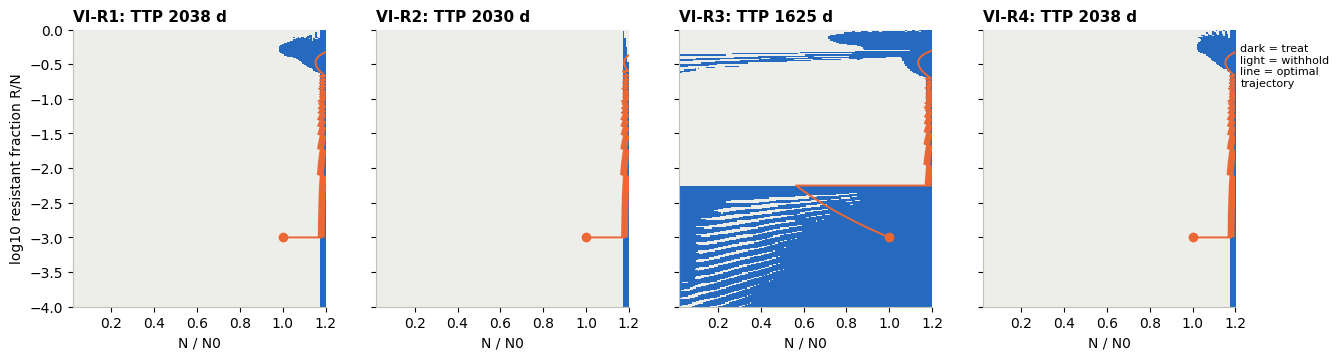

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
g = VI['R1']['grid']
for ax, o in zip(axs, OBJECTIVES):
    ax.imshow(VI[o]['pol'].T, origin='lower', aspect='auto', cmap=POLMAP, vmin=0, vmax=1, interpolation='nearest',
              extent=[g.N[0] / POP['N0'], g.N[-1] / POP['N0'], g.lf[0], g.lf[-1]])
    tr = rollout(VIP[f'VI-{o}'], [POP], record=True, objs=())['traj']
    N = tr['S'][:, 0] + tr['R'][:, 0]
    ax.plot(N / POP['N0'], np.log10(tr['R'][:, 0] / N), color=COL['R2'], lw=1.4)
    ax.plot(N[0] / POP['N0'], np.log10(tr['R'][0, 0] / N[0]), 'o', color=COL['R2'], ms=6)
    ax.set_title(f'VI-{o}: TTP {e2.loc[f"VI-{o}", "TTP"]:.0f} d'); ax.set_xlabel('N / N0'); ax.grid(False)
axs[0].set_ylabel('log10 resistant fraction R/N')
axs[-1].text(1.02, .95, 'dark = treat\nlight = withhold\nline = optimal\ntrajectory', transform=axs[-1].transAxes,
             fontsize=8, va='top')
save('E2_vi_policy_maps')

**Reading E2.** The ceilings are R1 2038 d, R2 2030 d, R3 1625 d and R4 2038 d.
- **VI-R1 and VI-R4 are the same policy, and VI-R2 is almost the same.** All three are *containment*: hold the tumour just under the progression line (mean burden 1.18 N₀), and treat only when the next week would cross it. Containment is what Viossat & Noble predict maximises TTP.
- **VI-R3 is different.** It treats at *any* burden while the resistant fraction is below about 0.55%, to leave the entropy-boundary penalty zone, and only then contains. That front-loaded treatment costs 413 days of TTP.
- R4 ≡ R1 is not an accident of this patient. E3c shows it also holds with a cost of resistance, and at 10× the durability weight once the give-up-early loophole is closed.

**At the optimum, the objective changes the policy for R3 and essentially not for R1, R2 or R4.**

## E3: Does each objective train stably?

The setup is PPO with 10 seeds per objective, all on the PoP patient. Every objective gets the **same** algorithm, architecture (2×128 tanh MLP, separate actor and critic), budget (10⁶ environment steps) and hyperparameters.

GAE λ = 0.99 for all four. With λ = 0.95, R3 collapsed to near-MTD on some seeds, because most of its signal is the distant, discounted progression penalty (see `decisions.md`). λ was changed for every objective at once, not tuned per objective.

Each agent is scored as a fraction of its own ceiling: (G − G_no-treatment) / (G_VI − G_no-treatment). An agent below 0.7 is flagged as *did not train* and excluded from the policy-space claims, as the Phase 2 doc requires.

In [10]:
E3 = run_many(jobs('E3'))
AG3 = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E3}
ev3 = split(evaluate(AG3))
ev3['own_score'] = [score(r[f'G_{r.obj}'], r.obj, FLOOR, CEIL) for _, r in ev3.iterrows()]
ok = ev3[ev3.own_score >= 0.7].copy()
print('did not train (< 0.7 of own ceiling):', list(ev3.policy[ev3.own_score < 0.7]) or 'none')
SUMMARY['E3'] = {o: dict(median_score=round(float(ev3[ev3.obj == o].own_score.median()), 3),
                         min_score=round(float(ev3[ev3.obj == o].own_score.min()), 3),
                         trained=int((ok.obj == o).sum())) for o in OBJECTIVES}
ev3.groupby('obj').agg(own_score=('own_score', miqr), worst_seed=('own_score', 'min'),
                       TTP=('TTP', miqr), n_trained=('own_score', lambda s: int((s >= .7).sum())))

did not train (< 0.7 of own ceiling): none


,own_score,worst_seed,TTP,n_trained
obj,,,,
R1,"0.867 [0.863, 0.871]",0.837,"1.74e+03 [1.73e+03, 1.75e+03]",10
R2,"0.848 [0.83, 0.848]",0.824,"1.73e+03 [1.72e+03, 1.74e+03]",10
R3,"0.763 [0.744, 0.774]",0.732,"1.49e+03 [1.45e+03, 1.55e+03]",10
R4,"0.868 [0.864, 0.872]",0.842,"1.75e+03 [1.74e+03, 1.76e+03]",10


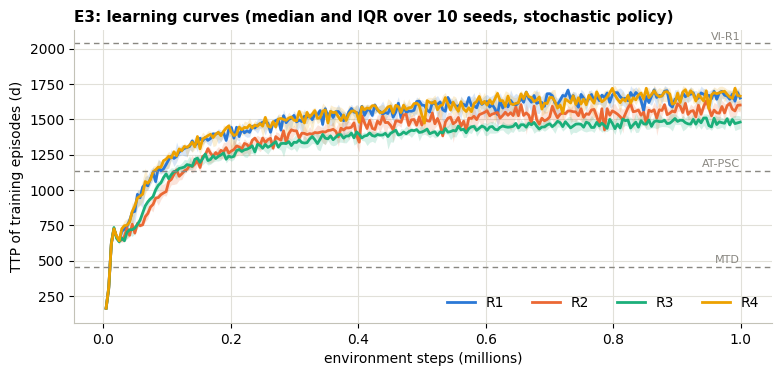

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = E3[0]['curve'][:, 0] / 1e6
for o in OBJECTIVES:
    q = np.nanpercentile(np.array([r['curve'][:, 1] for r in E3 if r['obj'] == o]), [25, 50, 75], axis=0)
    ax.fill_between(x, q[0], q[2], color=COL[o], alpha=.18, lw=0)
    ax.plot(x, q[1], color=COL[o], label=o)
for name, v in (('VI-R1', e2.loc['VI-R1', 'TTP']), (BEST_H, e1.loc[BEST_H, 'TTP']), ('MTD', e1.loc['MTD', 'TTP'])):
    ax.axhline(v, color=MUTED, ls=(0, (4, 3)), lw=1); ax.text(x[-1], v + 15, name, color=MUTED, va='bottom', ha='right', fontsize=8)
ax.set(xlabel='environment steps (millions)', ylabel='TTP of training episodes (d)',
       title='E3: learning curves (median and IQR over 10 seeds, stochastic policy)')
ax.legend(ncol=4, loc='lower right')
save('E3_learning_curves')

**Reading E3.** All 40 agents trained (≥ 0.7 of their own ceiling). The median scores are R1 0.87, R2 0.85, R3 0.76 and R4 0.87. Every objective's agents beat every heuristic (≈1740 d against the tuned AT-PSC's 1135 d) but stop about 15% short of their optimum. R3 is the hardest to learn and has the widest seed spread. Its value comes mostly from delaying a distant penalty (decisions D20).

## E4: Cross-evaluation (the core result)

Every agent is scored on every metric and on every objective's return. Values are median [IQR] over the seeds that trained, with greedy actions. The scientific content is in the **off-diagonal** of the score matrix: how much an agent trained on one objective loses on another objective's terms.

In [12]:
cols = ['TTP', 'dose', 'dose_pct', 'mean_fR', 'term_fR', 'mean_burden', 'regrow', 'f_holiday', 'G_R1', 'G_R2', 'G_R3', 'G_R4']
stoch = {k: float(np.median(rollout(Agent(r, greedy=False, seed=1), [POP] * 50, objs=())['TTP']))
         for k, r in zip(AG3, E3)}
ok['TTP_stochastic'] = ok.policy.map(stoch)
cross = ok.groupby('obj')[cols + ['TTP_stochastic']].agg(miqr)
ref = pd.concat([e1.loc[['None', 'MTD', 'AT50', BEST_AT, 'AT-PSC'], cols], e2[cols]]).map(lambda v: f'{v:.3g}')
cross_table = pd.concat([cross, ref])
cross_table.to_csv(f'{RES}/E4_cross_evaluation.csv')
cross_table

,TTP,dose,dose_pct,mean_fR,term_fR,mean_burden,regrow,f_holiday,G_R1,G_R2,G_R3,G_R4,TTP_stochastic
R1,"1.74e+03 [1.73e+03, 1.75e+03]","1.26e+03 [1.25e+03, 1.26e+03]","72 [72, 72.1]","0.0785 [0.0778, 0.0795]","0.465 [0.461, 0.474]","1.15 [1.15, 1.15]","0.0215 [0.0215, 0.0215]","0.465 [0.461, 0.474]","25.1 [25, 25.2]","-94.8 [-94.8, -94.7]","-84.9 [-85, -84.8]","20.3 [20.2, 20.4]","1.74e+03 [1.73e+03, 1.74e+03]"
R2,"1.73e+03 [1.72e+03, 1.74e+03]","1.24e+03 [1.22e+03, 1.24e+03]","71.5 [71.1, 71.7]","0.0741 [0.0705, 0.0762]","0.42 [0.399, 0.433]","1.16 [1.15, 1.16]","0.0215 [0.0215, 0.0215]","0.42 [0.399, 0.433]","24.9 [24.9, 25.1]","-94.7 [-94.8, -94.6]","-85 [-85.1, -84.9]","20.3 [20.1, 20.4]","1.64e+03 [1.62e+03, 1.66e+03]"
R3,"1.49e+03 [1.45e+03, 1.55e+03]","1.1e+03 [1.07e+03, 1.14e+03]","73.5 [73.4, 73.7]","0.0946 [0.0926, 0.0969]","0.547 [0.543, 0.557]","1.12 [1.11, 1.13]","0.0215 [0.0215, 0.0215]","0.547 [0.543, 0.557]","21.7 [21.1, 22.4]","-95.9 [-96, -95.7]","-85.2 [-85.6, -85]","17.4 [16.9, 18]","1.52e+03 [1.48e+03, 1.57e+03]"
R4,"1.75e+03 [1.74e+03, 1.76e+03]","1.26e+03 [1.25e+03, 1.26e+03]","71.9 [71.8, 72.1]","0.0773 [0.0763, 0.0784]","0.458 [0.448, 0.467]","1.15 [1.15, 1.16]","0.0215 [0.0215, 0.0215]","0.458 [0.448, 0.467]","25.2 [25.1, 25.3]","-94.7 [-94.7, -94.6]","-84.8 [-84.9, -84.8]","20.4 [20.3, 20.5]","1.74e+03 [1.74e+03, 1.76e+03]"
None,40.7,0,0,0.001,0.001,1.09,0.0215,0.001,0.649,-101,-100,0.399,NaN
MTD,452,452,100,0.386,0.976,0.559,0.0215,0.976,6.11,-101,-95.2,3.69,NaN
AT50,673,547,81.3,0.192,0.752,0.833,0.0215,0.752,9.94,-99.4,-92.1,7.3,NaN
AT90,932,708,76,0.132,0.608,0.983,0.0215,0.608,13.9,-98,-90.5,10.8,NaN
AT-PSC,1.14e+03,855,75.3,0.117,0.609,1.05,0.0215,0.609,16.8,-97.3,-88.6,13.2,NaN
VI-R1,2.04e+03,1.46e+03,71.8,0.073,0.469,1.18,0.0215,0.469,28.8,-93.7,-82.9,23.5,NaN


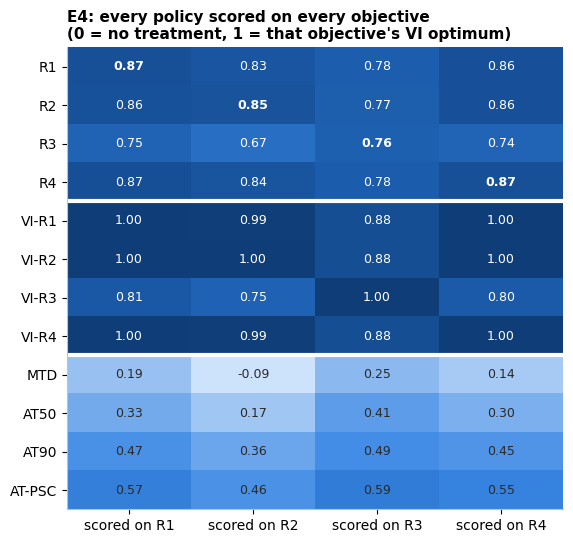

Cost of the wrong objective: loss on column objective when training on row objective


,R1,R2,R3,R4
R1,0.000,0.017,-0.014,0.005
R2,0.005,0.000,-0.012,0.006
R3,0.121,0.176,0.000,0.133
R4,-0.004,0.011,-0.019,0.000


In [13]:
def score_matrix(ok, e1, e2, floor, ceil, extra):
    # rows: agents per training objective (median over trained seeds), VI optima, baselines; cols: scoring objective
    rows = list(OBJECTIVES) + [f'VI-{o}' for o in OBJECTIVES] + extra
    M = pd.DataFrame(index=rows, columns=OBJECTIVES, dtype=float)
    for o in OBJECTIVES:
        for o2 in OBJECTIVES:
            M.loc[o, o2] = np.median(score(ok[ok.obj == o][f'G_{o2}'], o2, floor, ceil))
    for k in rows[4:]:
        src = e2 if k.startswith('VI') else e1
        for o2 in OBJECTIVES:
            M.loc[k, o2] = score(src.loc[k, f'G_{o2}'], o2, floor, ceil)
    loss = pd.DataFrame({o2: {o: M.loc[o2, o2] - M.loc[o, o2] for o in OBJECTIVES} for o2 in OBJECTIVES})
    return M, loss


def plot_score_matrix(ax, M, title):
    ax.imshow(M.values.clip(0, 1.05), cmap=BLUES, vmin=0, vmax=1.05, aspect='auto')
    for i in range(len(M)):
        for j in range(4):
            v = M.values[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9, color='white' if v > .6 else INK,
                    weight='bold' if i < 4 and i == j else 'normal')
    ax.set_xticks(range(4), [f'scored on {o}' for o in OBJECTIVES]); ax.set_yticks(range(len(M)), M.index)
    ax.axhline(3.5, color='white', lw=3); ax.axhline(7.5, color='white', lw=3); ax.grid(False)
    ax.set_title(title)


M, LOSS = score_matrix(ok, e1, e2, FLOOR, CEIL, ['MTD', 'AT50', BEST_AT, 'AT-PSC'])
M.to_csv(f'{RES}/E4_score_matrix.csv')
fig, ax = plt.subplots(figsize=(6.4, 6))
plot_score_matrix(ax, M, 'E4: every policy scored on every objective\n(0 = no treatment, 1 = that objective\'s VI optimum)')
save('E4_score_matrix')
print('Cost of the wrong objective: loss on column objective when training on row objective')
LOSS.round(3)

In [14]:
def ttp_tests(ok):
    have = [o for o in OBJECTIVES if (ok.obj == o).sum() >= 2]   # objectives with enough trained seeds
    kw = stats.kruskal(*[ok[ok.obj == o].TTP for o in have])
    pairs = []
    for a, b in itertools.combinations(have, 2):
        x, y = ok[ok.obj == a].TTP, ok[ok.obj == b].TTP
        pairs.append(dict(pair=f'{a} vs {b}', median_a=x.median(), median_b=y.median(),
                          diff=x.median() - y.median(), mannwhitney_p=stats.mannwhitneyu(x, y).pvalue))
    ic = stats.mannwhitneyu(ok[ok.obj == 'R3'].TTP, ok[ok.obj == 'R1'].TTP, alternative='greater')         if {'R1', 'R3'} <= set(have) else SimpleNamespace(pvalue=np.nan)
    print(f'Kruskal-Wallis on TTP across objectives: H = {kw.statistic:.2f}, p = {kw.pvalue:.2g}')
    print(f'Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = {ic.pvalue:.3g}',
          '-> HOLDS' if ic.pvalue < .05 else '-> does not hold')
    return kw, pd.DataFrame(pairs).set_index('pair'), ic


kw, pairs, ic = ttp_tests(ok)
SUMMARY['E4'] = dict(TTP_median={o: round(float(ok[ok.obj == o].TTP.median())) for o in OBJECTIVES},
                     kruskal_p=float(kw.pvalue), instrumental_convergence_p=float(ic.pvalue),
                     score_matrix=M.loc[list(OBJECTIVES)].round(3).to_dict(), loss=LOSS.round(3).to_dict())
pairs

Kruskal-Wallis on TTP across objectives: H = 25.76, p = 1.1e-05
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


,median_a,median_b,diff,mannwhitney_p
pair,,,,
R1 vs R2,1743.872,1726.106,17.765,1.620e-01
R1 vs R3,1743.872,1493.520,250.352,1.827e-04
R1 vs R4,1743.872,1750.770,-6.899,1.620e-01
R2 vs R3,1726.106,1493.520,232.587,1.827e-04
R2 vs R4,1726.106,1750.770,-24.664,1.726e-02
R3 vs R4,1493.520,1750.770,-257.251,1.827e-04


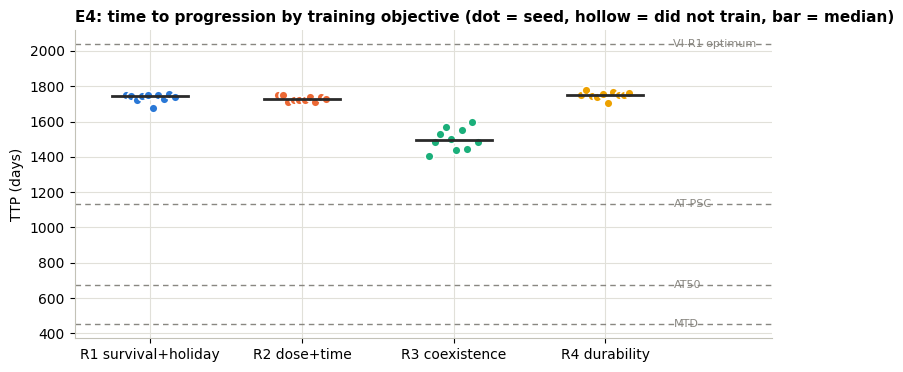

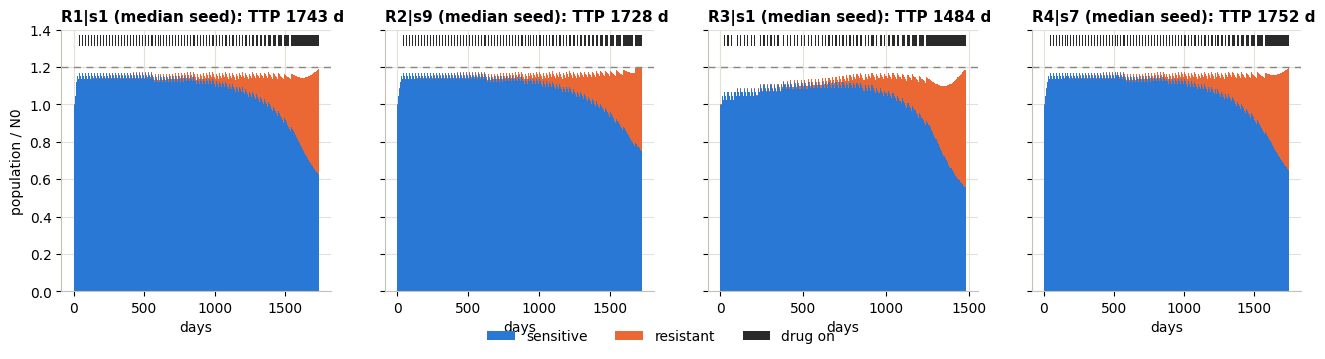

In [15]:
def plot_ttp(ax, ev, e1, e2, best_h, title):
    for i, o in enumerate(OBJECTIVES):
        d = ev[ev.obj == o]; jit = np.linspace(-.16, .16, len(d)); good = (d.own_score >= .7).values
        ax.scatter((i + jit)[good], d.TTP[good], s=40, color=COL[o], edgecolor='white', lw=1.2, zorder=3)
        ax.scatter((i + jit)[~good], d.TTP[~good], s=40, facecolor='none', edgecolor=COL[o], lw=1.4, zorder=3)
        if good.any():
            ax.plot([i - .25, i + .25], [d.TTP[good].median()] * 2, color=INK, lw=2, zorder=4)
    for name, v in (('VI-R1 optimum', e2.loc['VI-R1', 'TTP']), (best_h, e1.loc[best_h, 'TTP']),
                    ('AT50', e1.loc['AT50', 'TTP']), ('MTD', e1.loc['MTD', 'TTP'])):
        ax.axhline(v, color=MUTED, ls=(0, (4, 3)), lw=1); ax.text(3.45, v, name, color=MUTED, va='center', fontsize=8)
    ax.set_xticks(range(4), ['R1 survival+holiday', 'R2 dose+time', 'R3 coexistence', 'R4 durability'])
    ax.set_xlim(-.5, 4.1); ax.set_ylabel('TTP (days)'); ax.set_title(title)


fig, ax = plt.subplots(figsize=(9, 4))
plot_ttp(ax, ev3, e1, e2, BEST_H, 'E4: time to progression by training objective (dot = seed, hollow = did not train, bar = median)')
save('E4_ttp_by_objective')

fig, axs = plt.subplots(1, 4, figsize=(16, 3.4), sharey=True)
for ax, o in zip(axs, OBJECTIVES):
    d = ok[ok.obj == o]; k = d.iloc[(d.TTP - d.TTP.median()).abs().argmin()].policy
    composition(ax, AG3[k], f'{k} (median seed)', interval=7)
axs[0].set_ylabel('population / N0')
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(.5, -.08))
save('E4_trajectories')

**Reading E4, the core result.**
- **TTP.** R1, R2 and R4 agents reach ≈1726–1751 d, within 25 d of one another (Mann–Whitney p ≥ 0.017; none is significant after Bonferroni correction for six pairs). R3 agents reach 1494 d (Kruskal–Wallis p = 1·10⁻⁵; each pair with R3 p = 2·10⁻⁴).
- **Cost of the wrong objective** (loss table).
  - Training on R3 costs **0.12–0.18 of the optimum on every other objective**.
  - Training on R1, R2 or R4 costs ≤ 0.017 on one another.
  - It also costs *nothing* on R3. R1- and R4-trained agents score slightly **higher on R3's own objective** than R3-trained agents (0.78 vs 0.76), because most of R3's return is the discounted progression penalty, which survival-trained agents postpone better.
- **Instrumental convergence fails in the hypothesised direction** (one-sided p = 1). The coexistence-trained agent does not outlast the survival-trained one. The reverse holds: optimising survival is instrumentally good for the coexistence objective.
- The dose, resistant-fraction and burden columns show the same split: R3 runs a slightly higher resistant fraction and lower burden. Post-withdrawal regrowth is identical across all policies on this patient (decisions D3). On PoP, the fraction after a holiday (`f_holiday`) equals the terminal fraction, because with cost = 0 the composition does not change untreated.

## E5: Do the policies actually differ?

Outcome metrics can coincide while policies differ, so this is measured in **policy space** on a shared state set. That set is every state visited on the PoP patient by any E3 agent, VI policy or baseline. We report two things:
1. Gallagher's sigmoid threshold N* fitted to P(treat) against N/N₀. R² says how much of the policy burden alone explains.
2. Pairwise symmetric KL divergence between agents' action distributions.

The **noise floor** is the within-objective (seed-to-seed) divergence. A between-objective difference is real only if a label-permutation test says it exceeds that floor. Six pairs are tested, so we Bonferroni-correct to α = 0.05/6.

In [16]:
def boot_ci(x, n=5000, rng=np.random.default_rng(0)):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if not len(x):
        return np.array([np.nan, np.nan])
    return np.round(np.percentile(np.median(rng.choice(x, (n, len(x))), 1), [2.5, 97.5]), 3)


def perm_test(D, lab, a, b, n_perm=5000):
    # between-objective divergence minus within-objective (seed-to-seed) divergence, label-permutation null
    rng = np.random.default_rng(0)
    idx = np.where((lab == a) | (lab == b))[0]; L = lab[idx]; sub = D[np.ix_(idx, idx)]; iu = np.triu_indices(len(idx), 1)
    def stat(L):
        same = (L[:, None] == L[None, :])[iu]; return sub[iu][~same].mean() - sub[iu][same].mean(), sub[iu][same].mean()
    t0, within = stat(L)
    null = np.array([stat(rng.permutation(L))[0] for _ in range(n_perm)])
    return t0 + within, within, (np.sum(null >= t0) + 1) / (n_perm + 1)


def policy_space(p, agents, vip, base, ok, pairs=None):
    # shared state set = every state visited on patient p by any agent, VI policy or baseline
    pB, states = stack(p), []
    for pol in list(agents.values()) + list(vip.values()) + list(base.values()):
        tr = rollout(pol, [p], record=True, objs=())['traj']
        states.append(np.c_[tr['S'][:, 0], tr['R'][:, 0]])
    X = np.unique(np.round(np.concatenate(states), 5), axis=0)
    Sx, Rx = X[:, 0], X[:, 1]; nb = (Sx + Rx) / p['N0']
    P = {k: a.probs(Sx, Rx, pB) for k, a in agents.items()} | {k: v(Sx, Rx, 0.0, pB) for k, v in vip.items()}
    print(f'shared state set: {len(X)} states, N/N0 in [{nb.min():.2f}, {nb.max():.2f}]')
    thr = pd.DataFrame([dict(policy=k, **dict(zip(('N_star', 'slope', 'R2'), fit_threshold(nb, P[k])))) for k in P])
    thr_ag = split(thr[thr.policy.isin(ok.policy)])
    tab = thr_ag.groupby('obj').agg(N_star=('N_star', 'median'), slope=('slope', 'median'), R2_burden_only=('R2', 'median'))
    tab['N_star_95CI'] = [boot_ci(thr_ag[thr_ag.obj == o].N_star) for o in tab.index]
    tab = pd.concat([tab, thr[thr.policy.str.startswith('VI')].set_index('policy')[['N_star', 'slope', 'R2']]
                     .rename(columns={'R2': 'R2_burden_only'})])
    keys = list(ok.policy); lab = np.array([k.split('|')[0] for k in keys]); Pm = np.array([P[k] for k in keys])
    n = len(keys); KL = np.zeros((n, n)); DIS = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            KL[i, j] = KL[j, i] = sym_kl(Pm[i], Pm[j])
            DIS[i, j] = DIS[j, i] = np.mean((Pm[i] > .5) != (Pm[j] > .5))
    div = []
    for a, b in pairs or itertools.combinations(OBJECTIVES, 2):
        if min((lab == a).sum(), (lab == b).sum()) < 2:
            continue
        bk, wk, pk = perm_test(KL, lab, a, b); bd, wd, pd_ = perm_test(DIS, lab, a, b)
        div.append(dict(pair=f'{a} vs {b}', between_KL=bk, within_KL=wk, ratio=bk / max(wk, 1e-12), p_KL=pk,
                        between_disagree=bd, within_disagree=wd, p_disagree=pd_,
                        verdict='DIFFERENT policies' if pk < ALPHA and pd_ < ALPHA else 'not distinguishable from seed noise'))
    return dict(thr=thr_ag, tab=tab, KL=KL, DIS=DIS, lab=lab, div=pd.DataFrame(div).set_index('pair'))


ALPHA = .05 / 6
PS = policy_space(POP, AG3, VIP, BASE, ok)
tab5, div = PS['tab'], PS['div']
SUMMARY['E5_threshold'] = {k: round(float(v), 3) for k, v in tab5.N_star.items()}
SUMMARY['E5_divergence'] = div[['between_KL', 'within_KL', 'p_KL', 'between_disagree', 'within_disagree', 'verdict']].round(4).to_dict('index')
display(tab5)
div

shared state set: 7343 states, N/N0 in [0.19, 1.20]


,N_star,slope,R2_burden_only,N_star_95CI
R1,1.144,147.130,0.983,"[1.143, 1.146]"
R2,1.149,103.772,0.854,"[1.146, 1.151]"
R3,1.084,28.847,0.648,"[1.062, 1.11]"
R4,1.146,158.212,0.994,"[1.144, 1.148]"
VI-R1,1.174,194.475,0.316,NaN
VI-R2,1.176,10000.000,0.851,NaN
VI-R3,1.574,1.455,0.003,NaN
VI-R4,1.174,243.920,0.355,NaN


,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,0.179,0.013,14.124,5.999e-04,0.125,0.046,5.999e-04,DIFFERENT policies
R1 vs R3,0.643,0.041,15.533,5.999e-04,0.230,0.061,5.999e-04,DIFFERENT policies
R1 vs R4,0.023,0.018,1.268,5.959e-02,0.055,0.049,9.078e-02,not distinguishable from seed noise
R2 vs R3,1.141,0.043,26.397,5.999e-04,0.321,0.066,5.999e-04,DIFFERENT policies
R2 vs R4,0.141,0.020,7.166,5.999e-04,0.116,0.055,5.999e-04,DIFFERENT policies
R3 vs R4,0.763,0.048,15.774,5.999e-04,0.261,0.070,5.999e-04,DIFFERENT policies


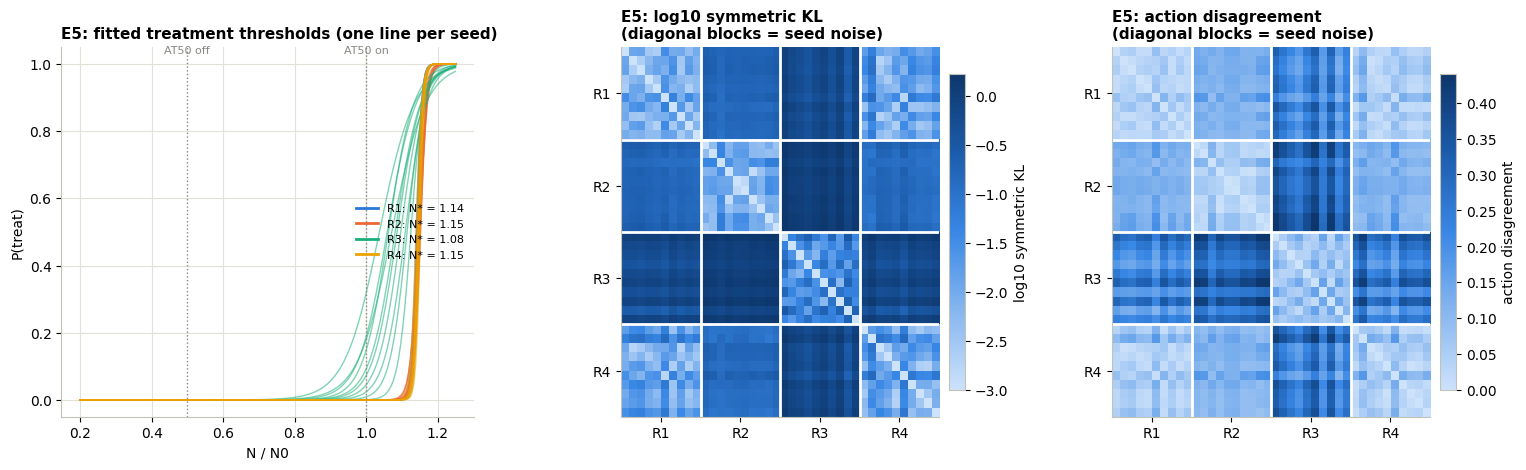

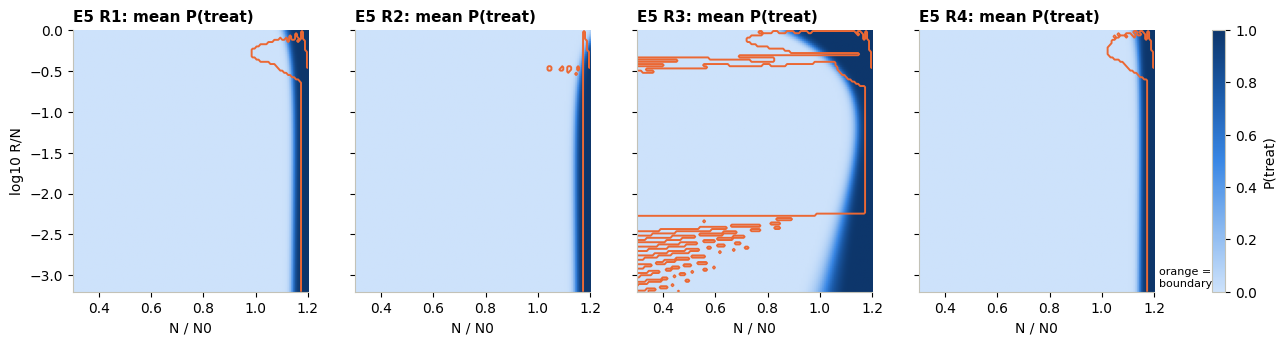

In [17]:
def plot_divergence(ps, prefix):
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw=dict(width_ratios=[1.2, 1, 1], wspace=.4))
    xs = np.linspace(.2, 1.25, 200)
    for _, r in ps['thr'].iterrows():
        axs[0].plot(xs, 1 / (1 + np.exp(-np.clip(r.slope * (xs - r.N_star), -50, 50))), color=COL[r.obj], lw=1, alpha=.55)
    for o in OBJECTIVES:
        axs[0].plot([], [], color=COL[o], label=f'{o}: N* = {ps["tab"].N_star.get(o, np.nan):.2f}')
    for v in (.5, 1.0):
        axs[0].axvline(v, color=MUTED, ls=':', lw=1)
    axs[0].text(.5, 1.03, 'AT50 off', color=MUTED, fontsize=8, ha='center'); axs[0].text(1.0, 1.03, 'AT50 on', color=MUTED, fontsize=8, ha='center')
    axs[0].set(xlabel='N / N0', ylabel='P(treat)', title=f'{prefix}: fitted treatment thresholds (one line per seed)')
    axs[0].legend(loc='center right', fontsize=8)
    lab = ps['lab']
    for ax, D, name in ((axs[1], np.log10(ps['KL'] + 1e-3), 'log10 symmetric KL'), (axs[2], ps['DIS'], 'action disagreement')):
        im = ax.imshow(D, cmap=BLUES, aspect='auto'); fig.colorbar(im, ax=ax, label=name, fraction=.046, pad=.03)
        edges = np.cumsum([np.sum(lab == o) for o in OBJECTIVES])[:-1] - .5
        for e in edges:
            ax.axhline(e, color='white', lw=2); ax.axvline(e, color='white', lw=2)
        mids = [np.mean(np.where(lab == o)[0]) for o in OBJECTIVES]
        ax.set_xticks(mids, OBJECTIVES); ax.set_yticks(mids, OBJECTIVES); ax.grid(False)
        ax.set_title(f'{prefix}: {name}\n(diagonal blocks = seed noise)')


def plot_agent_maps(p, agents, ok, vi, prefix):
    pB = stack(p)
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
    gN, glf = np.meshgrid(np.linspace(.3, 1.2, 120) * p['N0'], np.linspace(-3.2, 0, 120), indexing='ij')
    gS, gR = gN * (1 - 10 ** glf), gN * 10 ** glf
    for ax, o in zip(axs, OBJECTIVES):
        pm = np.mean([agents[k].probs(gS.ravel(), gR.ravel(), pB) for k in ok.policy[ok.obj == o]], 0).reshape(gN.shape)
        im = ax.imshow(pm.T, origin='lower', aspect='auto', cmap=BLUES, vmin=0, vmax=1, extent=[.3, 1.2, -3.2, 0])
        ax.contour(np.linspace(.3, 1.2, 120), np.linspace(-3.2, 0, 120),
                   Lookahead(vi[o])(gS.ravel(), gR.ravel(), 0, pB).reshape(gN.shape).T, levels=[.5], colors=COL['R2'], linewidths=1.4)
        ax.set_title(f'{prefix} {o}: mean P(treat)'); ax.set_xlabel('N / N0'); ax.grid(False)
    axs[0].set_ylabel('log10 R/N'); fig.colorbar(im, ax=axs, label='P(treat)', fraction=.02)
    axs[-1].text(1.02, .02, 'orange = VI\nboundary', transform=axs[-1].transAxes, fontsize=8)


plot_divergence(PS, 'E5'); save('E5_policy_divergence')
plot_agent_maps(POP, AG3, ok, VI, 'E5'); save('E5_agent_policy_maps')

**Reading E5.**
- **Thresholds.** The fitted thresholds are N\* = 1.144 (R1), 1.146 (R4), 1.149 (R2) and 1.084 (R3). All four lie above AT50's re-treatment point (1.0) and below the VI optimum's 1.17. The agents keep a safety margin that the exact optimum does not, and E8 shows what that margin buys.
- **Burden alone.** Burden alone explains R1/R4 policies almost completely (R² ≈ 0.98) but R3's much less (R² 0.64), because R3's policy depends on composition.
- **Divergence.** **Five of the six pairs differ beyond the seed-noise floor.** Only **R1 vs R4** is indistinguishable (KL ratio 1.27, p = 0.06; disagreement p = 0.09).
- **R1 vs R2 is the instructive case.** Their TTPs are statistically identical, but the policies disagree on 12.5% of shared states, against 4.6% between seeds of the same objective. *Outcome metrics hide policy differences*, which is the reason the Phase 2 design measures policy space.

**Verdict on the kill criterion:** the hypothesis survives. The objectives do produce different policies, except R1 vs R4, which E3c shows to be the same objective in effect.

## E6: Does coexistence mean anything useful with two populations?

On a two-population simplex, maximum Shannon entropy sits at S = R, i.e. 50% resistant. The faithful R3 port therefore rewards *growing* resistance up to half the tumour. The target-fraction variant rewards a resistant fraction within the same relative band (±2.6%) around f* ∈ {0.05, 0.1, 0.25}; f* = 0.5 is the faithful R3. It uses 5 seeds per f*, the same PPO, and a VI ceiling per f*.

In [18]:
FSTAR = {0.05: 'R3f0.05', 0.1: 'R3f0.1', 0.25: 'R3f0.25', 0.5: 'R3'}
objs6 = tuple(dict.fromkeys(OBJECTIVES + tuple(FSTAR.values())))
E6 = run_many(jobs('E6'))
AG6 = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E6} | {f'R3|s{s}': AG3[f'R3|s{s}'] for s in range(5)}
VI6 = {o: (VI['R3'] if o == 'R3' else solve_vi(o, POP)) for o in FSTAR.values()}
ev6 = split(evaluate(AG6, objs=objs6))
vi6 = evaluate({o: Lookahead(v) for o, v in VI6.items()}, objs=objs6).set_index('policy')
none6 = evaluate({'None': Const(0)}, objs=objs6).iloc[0]
ev6['own_score'] = [(r[f'G_{r.obj}'] - none6[f'G_{r.obj}']) / (vi6.loc[r.obj, f'G_{r.obj}'] - none6[f'G_{r.obj}'])
                    for _, r in ev6.iterrows()]
tab6 = pd.DataFrame({f: dict(agent_TTP=miqr(ev6[ev6.obj == o].TTP), agent_mean_fR=miqr(ev6[ev6.obj == o].mean_fR),
                             agent_dose_pct=miqr(ev6[ev6.obj == o].dose_pct), agent_own_score=miqr(ev6[ev6.obj == o].own_score),
                             VI_TTP=round(vi6.loc[o, 'TTP']), VI_mean_fR=round(vi6.loc[o, 'mean_fR'], 3))
                     for f, o in FSTAR.items()}).T
tab6.index.name = 'f*'
SUMMARY['E6'] = {str(f): dict(agent_TTP=round(float(ev6[ev6.obj == o].TTP.median())),
                              agent_mean_fR=round(float(ev6[ev6.obj == o].mean_fR.median()), 3),
                              VI_TTP=round(float(vi6.loc[o, 'TTP']))) for f, o in FSTAR.items()}
tab6

,agent_TTP,agent_mean_fR,agent_dose_pct,agent_own_score,VI_TTP,VI_mean_fR
f*,,,,,,
0.05,"1.51e+03 [1.45e+03, 1.51e+03]","0.0947 [0.0918, 0.0958]","73.5 [73.1, 73.5]","0.749 [0.745, 0.752]",1625,0.089
0.10,"1.52e+03 [1.51e+03, 1.57e+03]","0.0916 [0.0908, 0.0917]","73.1 [73.1, 73.2]","0.755 [0.751, 0.759]",1631,0.09
0.25,"1.51e+03 [1.51e+03, 1.52e+03]","0.0929 [0.092, 0.0944]","73.4 [73.1, 73.5]","0.749 [0.747, 0.764]",1631,0.09
0.50,"1.5e+03 [1.48e+03, 1.53e+03]","0.0937 [0.0931, 0.0954]","73.5 [73.5, 73.6]","0.759 [0.757, 0.766]",1625,0.092


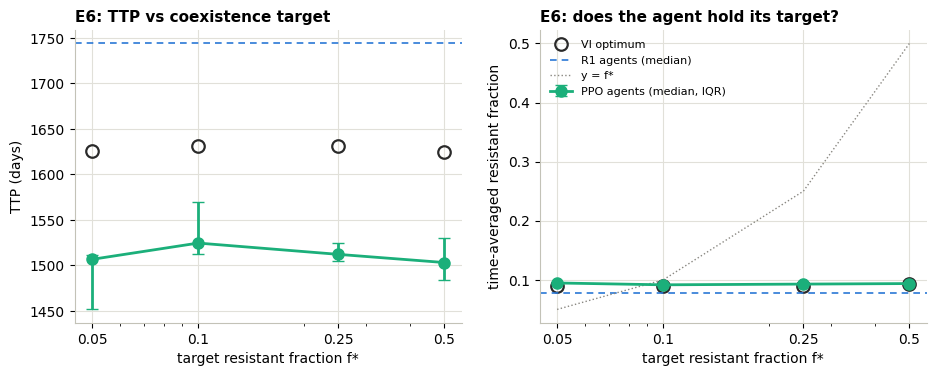

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
fs = np.array(list(FSTAR))
for ax, m, lab_ in ((axs[0], 'TTP', 'TTP (days)'), (axs[1], 'mean_fR', 'time-averaged resistant fraction')):
    q = np.array([np.percentile(ev6[ev6.obj == o][m], [25, 50, 75]) for o in FSTAR.values()])
    ax.errorbar(fs, q[:, 1], yerr=[q[:, 1] - q[:, 0], q[:, 2] - q[:, 1]], color=COL['R3'], marker='o', ms=8,
                capsize=4, label='PPO agents (median, IQR)')
    ax.plot(fs, [vi6.loc[o, m] for o in FSTAR.values()], 'o', mfc='none', mec=INK, ms=9, mew=1.6, label='VI optimum')
    ax.axhline(ok[ok.obj == 'R1'][m].median(), color=COL['R1'], ls=(0, (4, 3)), lw=1.2, label='R1 agents (median)')
    ax.set_xscale('log'); ax.set_xticks(fs, [str(f) for f in fs]); ax.set(xlabel='target resistant fraction f*', ylabel=lab_)
axs[1].plot(fs, fs, color=MUTED, lw=1, ls=':', label='y = f*')
axs[0].set_title('E6: TTP vs coexistence target'); axs[1].set_title('E6: does the agent hold its target?')
axs[1].legend(fontsize=8)
save('E6_fstar_sweep')

**E6b: why f\* barely matters here.** The resistant population's per-capita growth rate is r_R(1 − N/K) − d_T. It is negative only when N > K(1 − d_T/r_R). Strobl's bound says exactly when that threshold lies below the progression line 1.2 N₀.
- Below the bound (every patient who ever progresses, including PoP), R(t) **increases under every policy**. A resistant fraction can then be held at f\* only by growing S, which spends the progression budget.
- Above the bound, the patient is controllable, and a target fraction can actually be held.

The check below is VI only (no training), on PoP, on a patient below the bound and on a patient above it.

In [20]:
rows6b = []
for name, p in (('PoP (cost 0, turnover 0)', POP), ('below bound (cost .2, turnover .04)', patient(.2, .04)),
                ('above bound (cost .1, turnover .15)', patient(.1, .15))):
    for f, o in FSTAR.items():
        m = rollout(Lookahead(solve_vi(o, p)), [p], objs=(o,))
        rows6b.append(dict(patient=name, f_star=f, TTP=round(m['TTP'][0]), mean_fR=round(m['mean_fR'][0], 3),
                           terminal_fR=round(m['term_fR'][0], 3)))
e6b = pd.DataFrame(rows6b).set_index(['patient', 'f_star'])
SUMMARY['E6b'] = {f'{a} | f*={b}': r for (a, b), r in e6b.to_dict('index').items()}
e6b

TTP  mean_fR  terminal_fR
patient                             f_star                             
PoP (cost 0, turnover 0)            0.05     1625    0.089        0.451
                                    0.10     1631    0.090        0.459
                                    0.25     1631    0.090        0.461
                                    0.50     1625    0.092        0.494
below bound (cost .2, turnover .04) 0.05     3928    0.148        0.739
                                    0.10     3928    0.148        0.739
                                    0.25     3921    0.148        0.742
                                    0.50     3921    0.147        0.744
above bound (cost .1, turnover .15) 0.05    10950    0.049        0.049
                                    0.10    10950    0.097        0.098
                                    0.25    10950    0.243        0.250
                                    0.50    10950    0.485        0.499

**Reading E6.** Changing the coexistence target f\* changes **nothing** on PoP. Agents reach 1500–1520 d with a mean resistant fraction of about 0.09 at every f\*, and VI gives 1625–1631 d. E6b shows why.

Below Strobl's bound, R grows under every policy, so a target fraction cannot be held. Only R3's *boundary* penalty (escape f < 0.55% fast) and its progression penalty shape behaviour. Above the bound, VI holds every target exactly (mean f_R 0.049 / 0.097 / 0.243 / 0.485).

**Coexistence objectives only have teeth in patients who are controllable anyway.** In patients who progress, a two-population coexistence reward reduces to "treat early, then contain".

## E7: Does the ranking survive generalisation?

**Generalists** are trained on 20 virtual patients sampled (seed 1) from cost ∈ [0, 0.4] and turnover ∈ [0, 0.04]. This range keeps every patient below Strobl's controllability bound, so every patient eventually progresses under MTD. They are evaluated on 20 **held-out** patients (seed 2). The setup is 5 seeds per objective. E3's PoP-trained **specialists** are evaluated on the same held-out patients.

Rank stability: for each held-out patient and metric, we rank the four objectives by their seed-median value and compare that ranking with the PoP ranking from E4 (Kendall τ, plus how often the top objective is the same).

In [21]:
TRAIN, TEST = sample_cohort(20, TRAIN_COHORT_SEED), sample_cohort(20, TEST_COHORT_SEED)
E7 = run_many(jobs('E7'))
GEN = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E7}
SPEC = {f'{o}|s{s}': AG3[f'{o}|s{s}'] for o in OBJECTIVES for s in range(5)}
gen, spec = split(evaluate(GEN, TEST)), split(evaluate(SPEC, TEST))
base7 = evaluate({k: BASE[k] for k in ('MTD', 'AT50', BEST_AT, BEST_H)}, TEST)
vi7 = np.array([rollout(Lookahead(solve_vi('R1', p)), [p], objs=())['TTP'][0] for p in TEST])

RANK_METRICS = ['TTP', 'dose', 'mean_fR', 'regrow', 'f_holiday', 'G_R1', 'G_R2', 'G_R3', 'G_R4']
pop_med = ok.groupby('obj')[RANK_METRICS].median().loc[list(OBJECTIVES)]


def rank_stability(df):
    med = df.groupby(['patient', 'obj'])[RANK_METRICS].median()
    out = {}
    for m in RANK_METRICS:
        taus, top, bot = [], [], []
        for i in df.patient.unique():
            v = med.loc[i][m].loc[list(OBJECTIVES)]
            taus.append(stats.kendalltau(pop_med[m], v).statistic)
            top.append(v.idxmax() == pop_med[m].idxmax()); bot.append(v.idxmin() == pop_med[m].idxmin())
        taus = np.array(taus, float)   # nan when PoP values are all tied (regrow on PoP, see decisions D3)
        out[m] = dict(mean_kendall_tau=taus[~np.isnan(taus)].mean() if (~np.isnan(taus)).any() else np.nan,
                      same_top_objective=np.mean(top), same_bottom_objective=np.mean(bot))
    return pd.DataFrame(out).T


t7 = pd.DataFrame({'generalist_TTP': gen.groupby('obj').TTP.agg(miqr), 'specialist_TTP': spec.groupby('obj').TTP.agg(miqr),
                   'generalist_TTP / VI-R1': [miqr(gen[gen.obj == o].TTP.values / np.tile(vi7, (gen.obj == o).sum() // len(TEST)))
                                              for o in OBJECTIVES]}, index=list(OBJECTIVES))
for k in ('MTD', 'AT50', BEST_AT, BEST_H):
    t7.loc[k] = [miqr(base7[base7.policy == k].TTP), '', miqr(base7[base7.policy == k].TTP.values / vi7)]
rs7 = pd.concat({'generalists': rank_stability(gen), 'specialists': rank_stability(spec)}, axis=1)
SUMMARY['E7'] = dict(generalist_TTP={o: round(float(gen[gen.obj == o].TTP.median())) for o in OBJECTIVES},
                     specialist_TTP={o: round(float(spec[spec.obj == o].TTP.median())) for o in OBJECTIVES},
                     VI_R1_TTP_median=round(float(np.median(vi7))),
                     rank_stability={'/'.join(k): v for k, v in rs7.round(3).to_dict().items()})
display(t7)
rs7

,generalist_TTP,specialist_TTP,generalist_TTP / VI-R1
R1,"2.65e+03 [2.32e+03, 2.9e+03]","2.77e+03 [2.45e+03, 2.99e+03]","0.727 [0.694, 0.777]"
R2,"2.8e+03 [2.46e+03, 3.09e+03]","2.84e+03 [2.47e+03, 3.09e+03]","0.771 [0.743, 0.814]"
R3,"2.07e+03 [1.86e+03, 2.27e+03]","2.27e+03 [2.04e+03, 2.49e+03]","0.571 [0.535, 0.63]"
R4,"2.78e+03 [2.46e+03, 3.02e+03]","2.83e+03 [2.48e+03, 3.1e+03]","0.767 [0.739, 0.821]"
MTD,"553 [519, 602]",,"0.151 [0.139, 0.188]"
AT50,"901 [757, 949]",,"0.238 [0.221, 0.279]"
AT90,"1.3e+03 [1.19e+03, 1.43e+03]",,"0.355 [0.33, 0.422]"
AT-PSC,"1.6e+03 [1.48e+03, 1.78e+03]",,"0.454 [0.415, 0.524]"


generalists                                               specialists                                         
          mean_kendall_tau same_top_objective same_bottom_objective mean_kendall_tau same_top_objective same_bottom_objective
TTP                  0.600               0.80                  1.00            0.533               0.40                  1.00
dose                 0.600               0.80                  1.00            0.750               0.70                  1.00
mean_fR              0.617               1.00                  0.25            0.483               0.95                  0.55
regrow                 NaN               0.00                  0.00              NaN               0.00                  0.00
f_holiday            1.000               1.00                  1.00            0.950               1.00                  1.00
G_R1                 0.583               0.75                  1.00            0.450               0.25                  1.00
G_R2                 0.733               0.20                  1.00            1.000               1.00                  1.00
G_R3                 0.433               0.30                  1.00            0.446               0.20                  1.00
G_R4                 0.650               0.95                  1.00            0.400               0.10                  1.00

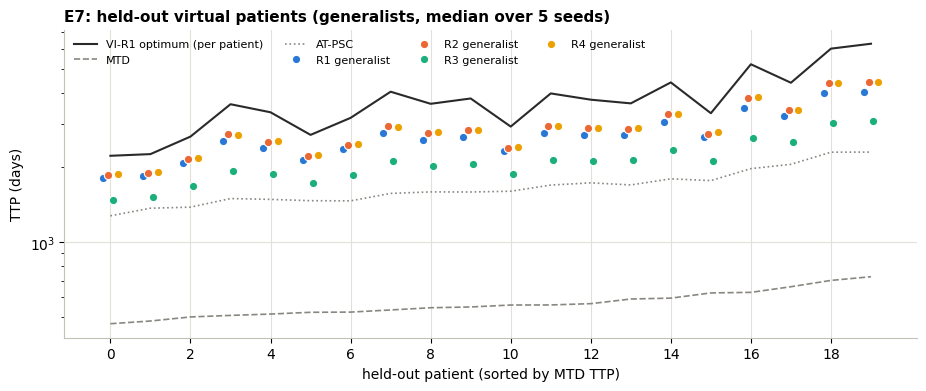

In [22]:
order = np.argsort(base7[base7.policy == 'MTD'].TTP.values)
fig, ax = plt.subplots(figsize=(11, 4))
xi = np.arange(len(TEST))
ax.plot(xi, vi7[order], color=INK, lw=1.5, label='VI-R1 optimum (per patient)')
ax.plot(xi, base7[base7.policy == 'MTD'].TTP.values[order], color=MUTED, lw=1.2, ls='--', label='MTD')
ax.plot(xi, base7[base7.policy == BEST_H].TTP.values[order], color=MUTED, lw=1.2, ls=':', label=BEST_H)
for k, o in enumerate(OBJECTIVES):
    med = gen[gen.obj == o].groupby('patient').TTP.median().values[order]
    ax.plot(xi + (k - 1.5) * .12, med, 'o', color=COL[o], ms=6, mec='white', mew=.8, label=f'{o} generalist')
ax.set_xticks(xi[::2])
ax.set(xlabel='held-out patient (sorted by MTD TTP)', ylabel='TTP (days)', yscale='log',
       title='E7: held-out virtual patients (generalists, median over 5 seeds)')
ax.legend(ncol=4, fontsize=8, loc='upper left')
save('E7_cohort')

**Reading E7.**
- **Generalists.** They reach 2650–2800 d on held-out patients, far above AT-PSC (1600 d) and MTD (553 d). That is 57–77% of each patient's own VI-R1 optimum.
- **Specialists generalise better.** Specialists trained on the single PoP patient do **slightly better** than the generalists (e.g. R1: 2770 vs 2650 d). The containment rule learned on one patient transfers without retraining.
- **Ranking.** The order among R1, R2 and R4 is not stable: R2 tops TTP on the cohort, and Kendall τ ≈ 0. **R3 is last on TTP for 20 of 20 held-out patients** under both training schemes. The ranking that survives generalisation is "R3 vs the rest", not the order within the rest.

## E8: Is the ranking an artefact of one parameter set?

This is the Eastman protocol: the PoP patient's kinetic parameters (r_S, r_R, d_D, f_R) are each scaled by an independent U[1−p, 1+p], for p ∈ {15, 20, 25}%, giving 50 patients per level. The E3 agents and the VI policies, which plan with the *nominal* model, are evaluated without retraining. Because r_R is perturbed independently of r_S, the cost of resistance can become negative (resistant cells fitter than sensitive ones).

In [23]:
PCOL = {o: [k for k in ok.policy if k.startswith(o + '|')] for o in OBJECTIVES}
rows8, rank8 = [], {}
for frac in (0.15, 0.20, 0.25):
    pts = perturb(POP, frac, 50, seed=int(round(frac * 100)))
    d = split(evaluate({k: AG3[k] for k in ok.policy}, pts))
    b = evaluate({k: BASE[k] for k in ('MTD', 'AT50', BEST_AT, BEST_H)} | VIP, pts)
    for o in OBJECTIVES:
        rows8.append(dict(perturbation=frac, policy=f'{o} agents', TTP=miqr(d[d.obj == o].groupby('patient').TTP.median()),
                          own_score_vs_nominal_ceiling=miqr(score(d[d.obj == o][f'G_{o}'], o, FLOOR, CEIL))))
    for k in ('MTD', 'AT50', BEST_AT, BEST_H, 'VI-R1', 'VI-R3'):
        rows8.append(dict(perturbation=frac, policy=k, TTP=miqr(b[b.policy == k].TTP), own_score_vs_nominal_ceiling=''))
    rank8[frac] = rank_stability(d)
e8 = pd.DataFrame(rows8).set_index(['perturbation', 'policy'])
rs8 = pd.concat(rank8, axis=1).xs('mean_kendall_tau', axis=1, level=1)
rs8.columns = [f'tau at +/-{int(f * 100)}%' for f in rs8.columns]
SUMMARY['E8'] = dict(kendall_tau=rs8.round(3).to_dict())
display(e8)
rs8

TTP own_score_vs_nominal_ceiling
perturbation policy                                                               
0.15         R1 agents  1.68e+03 [1.59e+03, 1.83e+03]         0.841 [0.783, 0.905]
             R2 agents  1.67e+03 [1.58e+03, 1.84e+03]         0.803 [0.697, 0.951]
             R3 agents  1.45e+03 [1.37e+03, 1.56e+03]         0.738 [0.694, 0.783]
             R4 agents   1.69e+03 [1.6e+03, 1.84e+03]         0.841 [0.801, 0.905]
             MTD                       456 [419, 478]                             
             AT50                      653 [606, 687]                             
             AT90                      894 [859, 977]                             
             AT-PSC      1.16e+03 [1.1e+03, 1.24e+03]                             
             VI-R1           1.68e+03 [108, 2.01e+03]                             
             VI-R3           1.35e+03 [323, 1.58e+03]                             
0.20         R1 agents  1.73e+03 [1.51e+03, 1.98e+03]         0.862 [0.737, 0.964]
             R2 agents  1.73e+03 [1.51e+03, 1.98e+03]          0.812 [0.493, 1.07]
             R3 agents   1.5e+03 [1.31e+03, 1.69e+03]         0.756 [0.668, 0.832]
             R4 agents  1.74e+03 [1.52e+03, 1.99e+03]         0.867 [0.778, 0.972]
             MTD                       475 [443, 516]                             
             AT50                      663 [614, 762]                             
             AT90                 940 [834, 1.05e+03]                             
             AT-PSC      1.18e+03 [1.07e+03, 1.3e+03]                             
             VI-R1           1.59e+03 [159, 2.09e+03]                             
             VI-R3           1.29e+03 [287, 1.63e+03]                             
0.25         R1 agents   1.7e+03 [1.52e+03, 2.02e+03]             0.829 [0.763, 1]
             R2 agents     1.69e+03 [1.51e+03, 2e+03]           0.86 [0.698, 1.06]
             R3 agents  1.45e+03 [1.31e+03, 1.71e+03]         0.729 [0.664, 0.844]
             R4 agents  1.72e+03 [1.52e+03, 2.04e+03]         0.847 [0.755, 0.978]
             MTD                       459 [407, 517]                             
             AT50                      633 [572, 734]                             
             AT90                 894 [806, 1.05e+03]                             
             AT-PSC     1.16e+03 [1.01e+03, 1.32e+03]                             
             VI-R1           1.63e+03 [112, 2.03e+03]                             
             VI-R3           1.21e+03 [244, 1.58e+03]

,tau at +/-15%,tau at +/-20%,tau at +/-25%
TTP,0.760,0.747,0.800
dose,0.893,0.927,0.933
mean_fR,0.947,0.947,0.933
regrow,NaN,NaN,NaN
f_holiday,0.973,0.953,0.920
G_R1,0.667,0.700,0.693
G_R2,0.967,0.920,0.953
G_R3,0.858,0.903,0.918
G_R4,0.533,0.607,0.567


**Reading E8.** Under ±15–25% kinetic perturbation, the agents' median TTP holds at 1680–1740 d (R3: 1450–1500 d). AT-PSC stays at about 1160 d.

The **exact VI optimum, planning with the nominal model, is brittle.** Its lower quartile collapses to 110–160 d. It parks the tumour at 1.18 N₀ with almost no margin, so growth faster than modelled crosses the line within a week or two. The PPO agents' lower threshold (E5) is what makes them robust. That echoes Eastman 2021: RL's advantage is robustness, not peak performance. R3-last persists, and the TTP rank correlation with the nominal patient is τ ≈ 0.45.

## E9: Does the objective ranking depend on monitoring cadence?

Agents are trained at decision intervals of 1, 7 (from E3) and 28 days, with 5 seeds each, and every one is evaluated at 1, 7 and 28 days. γ is rescaled to γ_Δ = 0.999^(Δ/7), so the horizon stays fixed **in days**. The step budget is the same 10⁶ steps at every cadence. Daily agents therefore see 7× fewer simulated days than weekly agents, a confound noted in `decisions.md`. Gallagher found that training at a lower frequency helped, and that evaluating at a lower frequency than training failed.

In [24]:
E9 = run_many(jobs('E9'))
AG9 = {(r['interval'], r['obj'], r['seed']): Agent(r) for r in E9}
AG9 |= {(7, o, s): AG3[f'{o}|s{s}'] for o in OBJECTIVES for s in range(5)}
rows9 = []
for (dtr, o, s), a in AG9.items():
    for dev in (1, 7, 28):
        m = rollout(a, [POP], interval=dev, objs=(o,))
        rows9.append(dict(train=dtr, eval=dev, obj=o, seed=s, TTP=m['TTP'][0], G=m[f'G_{o}'][0]))
e9 = pd.DataFrame(rows9)
mat9 = e9.groupby(['obj', 'train', 'eval']).TTP.median().unstack()

# did each (objective, training cadence) actually train? score against the VI optimum at that cadence
fl9 = {(o, d): rollout(Const(0), [POP], interval=d, objs=(o,))[f'G_{o}'][0] for o in OBJECTIVES for d in (1, 7, 28)}
vi9 = {(o, d): rollout(Lookahead(solve_vi(o, POP, interval=d)), [POP], interval=d, objs=(o,)) for o in OBJECTIVES for d in (1, 7, 28)}
own9 = e9[e9.train == e9['eval']].copy()   # e9.eval would be DataFrame.eval, not the column
own9['own_score'] = [(r.G - fl9[(r.obj, r.train)]) / (vi9[(r.obj, r.train)][f'G_{r.obj}'][0] - fl9[(r.obj, r.train)])
                     for r in own9.itertuples()]
score9 = own9.groupby(['obj', 'train']).own_score.median().unstack()
print('(objective, training cadence) below 0.7 of that cadence\'s optimum - did not train:',
      [f'{o} @ {d} d' for o in OBJECTIVES for d in (1, 7, 28) if score9.loc[o, d] < .7] or 'none')
ref9 = pd.DataFrame({dev: dict(AT50=rollout(ATx(.5), [POP], interval=dev, objs=())['TTP'][0],
                               **{f'VI-{o}': vi9[(o, dev)]['TTP'][0] for o in OBJECTIVES}) for dev in (1, 7, 28)})
SUMMARY['E9'] = dict(matrix={f'{o}_train{t}': {str(k): round(float(v)) for k, v in mat9.loc[(o, t)].items()}
                             for o, t in mat9.index},
                     own_score_at_training_cadence={o: {str(d): round(float(score9.loc[o, d]), 3) for d in (1, 7, 28)} for o in OBJECTIVES},
                     reference={str(k): v for k, v in ref9.round(0).to_dict().items()})
display(score9.round(3).rename_axis(columns='trained at (own score vs VI at that cadence)'))
display(ref9.round(0))
mat9.round(0)

(objective, training cadence) below 0.7 of that cadence's optimum - did not train: ['R1 @ 1 d', 'R2 @ 1 d', 'R3 @ 1 d', 'R4 @ 1 d']


trained at (own score vs VI at that cadence),1,7,28
obj,,,
R1,0.677,0.869,1.000
R2,0.589,0.848,0.929
R3,0.232,0.759,0.894
R4,0.669,0.868,1.000


,1,7,28
AT50,663.0,673.0,671.0
VI-R1,2233.0,2038.0,1400.0
VI-R2,2178.0,2030.0,1400.0
VI-R3,1759.0,1625.0,1183.0
VI-R4,2233.0,2038.0,1400.0


eval           1       7       28
obj train                        
R1  1      1467.0  1524.0    83.0
    7      1685.0  1745.0    83.0
    28     1253.0  1295.0  1401.0
R2  1      1439.0  1485.0   418.0
    7      1689.0  1723.0    83.0
    28     1249.0  1292.0  1230.0
R3  1       452.0   452.0   452.0
    7      1449.0  1503.0   418.0
    28     1028.0  1055.0  1125.0
R4  1      1472.0  1526.0    83.0
    7      1690.0  1748.0    83.0
    28     1275.0  1301.0  1401.0

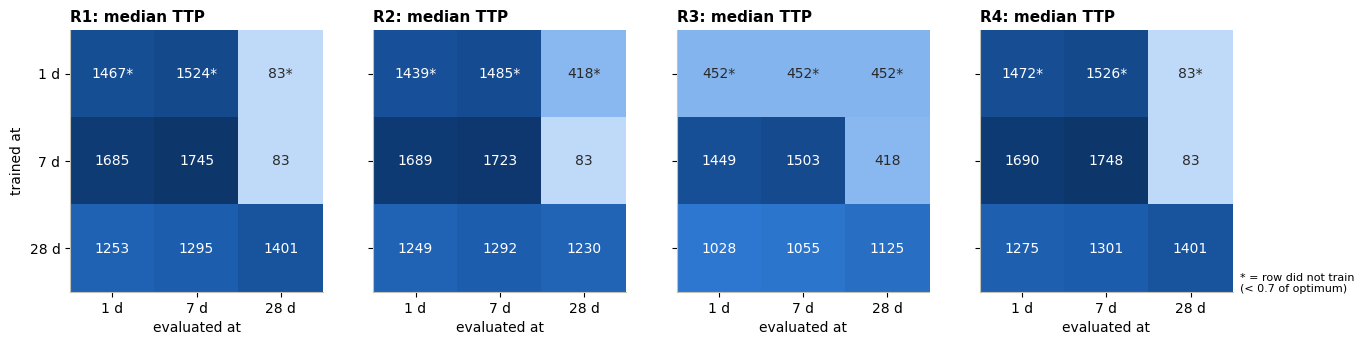

In [25]:
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
vmax = np.nanmax(mat9.values)
for ax, o in zip(axs, OBJECTIVES):
    m = mat9.loc[o].values
    ax.imshow(m, cmap=BLUES, vmin=0, vmax=vmax, aspect='auto')
    for i in range(3):
        for j in range(3):
            flag = '*' if score9.loc[o, (1, 7, 28)[i]] < .7 else ''
            ax.text(j, i, f'{m[i, j]:.0f}{flag}', ha='center', va='center', color='white' if m[i, j] > .55 * vmax else INK)
    ax.set_xticks(range(3), ['1 d', '7 d', '28 d']); ax.set_yticks(range(3), ['1 d', '7 d', '28 d'])
    ax.set_xlabel('evaluated at'); ax.set_title(f'{o}: median TTP'); ax.grid(False)
axs[0].set_ylabel('trained at'); axs[-1].text(1.03, 0, '* = row did not train\n(< 0.7 of optimum)', transform=axs[-1].transAxes, fontsize=8)
save('E9_cadence')

**Reading E9.** Gallagher's asymmetry replicates.
- Agents trained weekly (or daily) **fail catastrophically when evaluated monthly** (83 d). They hold N near 1.15 N₀ and progress before the first re-check.
- Evaluating at a *higher* frequency than training is harmless.
- Monthly-trained agents are the only ones that survive monthly monitoring (1125–1401 d), and they essentially reach the monthly optimum (own score 0.89–1.00). The price is lower TTP at finer cadences, because they keep a bigger margin.
- **No daily-trained agent reached 0.7 of the daily optimum** (R1 0.68, R2 0.59, R4 0.67; R3 0.23, collapsed to MTD at 452 d), so every daily row is starred. With a fixed 10⁶-step budget, daily agents see 7× fewer simulated days (decisions D29). This means daily training is under-budgeted, not that daily monitoring is bad.

The objective ranking holds at every cadence that trained. At 28 days: R3 (1125 d) < R2 (1230 d) < R1 ≈ R4 (1401 d).

## E10: Does any of this survive model misspecification?

This is evaluation-only transfer of the PoP-trained E3 agents (and of the PoP-trained E7 generalists, on the held-out cohort) to two one-line changes of the drug term:
- **cytostatic**: the drug can at most arrest sensitive proliferation, (1 − d_D·D) → max(0, 1 − d_D·D).
- **log-kill**: kill is independent of growth, matched to Strobl's net kill rate at N₀.

The ceilings are re-solved by VI in each transfer environment (VI*). Following Aif 2025, we also check whether agents that are good in the training environment stay good in the new one, using a Spearman correlation across agents.

In [26]:
DRUGS = ('cytotoxic', 'cytostatic', 'logkill')
E10, rows10 = {}, []
for drug in DRUGS:
    pols = {k: BASE[k] for k in ('None', 'MTD', 'AT50', BEST_AT, BEST_H)} | VIP
    pols |= {f'VI*-{o}': Lookahead(solve_vi(o, POP, drug=drug)) for o in OBJECTIVES}
    b = evaluate(pols, drug=drug).set_index('policy')
    a = split(evaluate({k: AG3[k] for k in ok.policy}, drug=drug))
    fl = {o: b.loc['None', f'G_{o}'] for o in OBJECTIVES}; ce = {o: b.loc[f'VI*-{o}', f'G_{o}'] for o in OBJECTIVES}
    a['own_score'] = [score(r[f'G_{r.obj}'], r.obj, fl, ce) for _, r in a.iterrows()]
    E10[drug] = (a, b)
    for o in OBJECTIVES:
        rows10.append(dict(env=drug, policy=f'{o} agents', TTP=miqr(a[a.obj == o].TTP), own_score=miqr(a[a.obj == o].own_score)))
    for k in ('None', 'MTD', 'AT50', BEST_AT, BEST_H, 'VI-R1', 'VI*-R1', 'VI*-R3'):
        rows10.append(dict(env=drug, policy=k, TTP=f"{b.loc[k, 'TTP']:.0f}", own_score=''))
e10 = pd.DataFrame(rows10).set_index(['env', 'policy'])

corr = {}
base_a = E10['cytotoxic'][0].set_index('policy')
for drug in DRUGS[1:]:
    t = E10[drug][0].set_index('policy')
    corr[drug] = dict(spearman_TTP=stats.spearmanr(base_a.TTP, t.loc[base_a.index].TTP).statistic,
                      spearman_own_score=stats.spearmanr(base_a.own_score, t.loc[base_a.index].own_score).statistic,
                      objective_rank_tau_TTP=stats.kendalltau(base_a.groupby('obj').TTP.median(),
                                                              t.groupby('obj').TTP.median()).statistic)
corr = pd.DataFrame(corr).T

gen10 = {drug: split(evaluate(GEN, TEST, drug=drug, objs=())).groupby('obj').TTP.median() for drug in DRUGS}
gen10 = pd.DataFrame(gen10)
SUMMARY['E10'] = dict(agents_TTP={d: {o: round(float(E10[d][0][E10[d][0].obj == o].TTP.median())) for o in OBJECTIVES} for d in DRUGS},
                      baselines_TTP={d: {k: round(float(E10[d][1].loc[k, 'TTP'])) for k in ('MTD', 'AT50', BEST_AT, BEST_H, 'VI*-R1')} for d in DRUGS},
                      correlation=corr.round(3).to_dict('index'), generalists_test_cohort=gen10.round(0).to_dict())
display(e10)
display(corr.round(3))
gen10.round(0)

C:\Users\Arnav Kumar\AppData\Roaming\Python\Python314\site-packages\numpy\lib\_nanfunctions_impl.py:1396: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


TTP             own_score
env        policy                                                        
cytotoxic  R1 agents  1.74e+03 [1.73e+03, 1.75e+03]  0.867 [0.863, 0.871]
           R2 agents  1.73e+03 [1.72e+03, 1.74e+03]   0.848 [0.83, 0.848]
           R3 agents  1.49e+03 [1.45e+03, 1.55e+03]  0.763 [0.744, 0.774]
           R4 agents  1.75e+03 [1.74e+03, 1.76e+03]  0.868 [0.864, 0.872]
           None                                  41                      
           MTD                                  452                      
           AT50                                 673                      
           AT90                                 932                      
           AT-PSC                              1135                      
           VI-R1                               2038                      
           VI*-R1                              2038                      
           VI*-R3                              1625                      
cytostatic R1 agents  1.13e+03 [1.13e+03, 1.13e+03]     1.01 [1.01, 1.01]
           R2 agents  1.13e+03 [1.13e+03, 1.13e+03]        nan [nan, nan]
           R3 agents  1.05e+03 [1.02e+03, 1.07e+03]   0.95 [0.943, 0.952]
           R4 agents  1.13e+03 [1.13e+03, 1.13e+03]     1.01 [1.01, 1.01]
           None                                  41                      
           MTD                                  919                      
           AT50                                 919                      
           AT90                                 919                      
           AT-PSC                              1126                      
           VI-R1                                998                      
           VI*-R1                              1113                      
           VI*-R3                               967                      
logkill    R1 agents  1.73e+03 [1.73e+03, 1.74e+03]  0.834 [0.832, 0.838]
           R2 agents  1.66e+03 [1.63e+03, 1.68e+03]  0.781 [0.776, 0.785]
           R3 agents  1.48e+03 [1.45e+03, 1.53e+03]   0.749 [0.73, 0.761]
           R4 agents  1.75e+03 [1.74e+03, 1.75e+03]  0.861 [0.857, 0.861]
           None                                  41                      
           MTD                                  828                      
           AT50                                 828                      
           AT90                                 947                      
           AT-PSC                              1192                      
           VI-R1                               1922                      
           VI*-R1                              2045                      
           VI*-R3                              1715

,spearman_TTP,spearman_own_score,objective_rank_tau_TTP
cytostatic,0.760,NaN,0.707
logkill,0.894,0.905,1.000


,cytotoxic,cytostatic,logkill
obj,,,
R1,2651.0,2537.0,2552.0
R2,2804.0,2630.0,2736.0
R3,2075.0,2021.0,2033.0
R4,2782.0,2646.0,2704.0


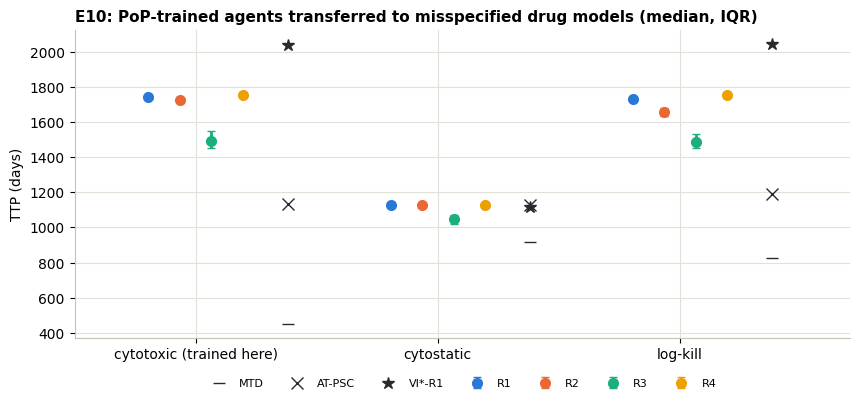

In [27]:
fig, ax = plt.subplots(figsize=(10, 4))
for i, drug in enumerate(DRUGS):
    a, b = E10[drug]
    for k, o in enumerate(OBJECTIVES):
        q = np.percentile(a[a.obj == o].TTP, [25, 50, 75]); x = i + (k - 1.5) * .13
        ax.errorbar(x, q[1], yerr=[[q[1] - q[0]], [q[2] - q[1]]], fmt='o', color=COL[o], ms=7, capsize=3,
                    label=o if i == 0 else None)
    for name, mk in (('MTD', '_'), (BEST_H, 'x'), ('VI*-R1', '*')):
        ax.plot(i + .38, b.loc[name, 'TTP'], mk, color=INK, ms=9, label=name if i == 0 else None)
ax.set_xticks(range(3), ['cytotoxic (trained here)', 'cytostatic', 'log-kill']); ax.set_xlim(-.5, 2.7)
ax.set(ylabel='TTP (days)', title='E10: PoP-trained agents transferred to misspecified drug models (median, IQR)')
ax.legend(ncol=7, fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.1))
save('E10_transfer')

**Reading E10.**
- **Log-kill.** The agents transfer almost unchanged: R1/R4 1730–1750 d (vs ≈1745–1750 d in the training environment), R2 1660 d, R3 1480 d. MTD falls to 828 d, and AT50 becomes identical to MTD because the tumour never reaches 0.5 N₀. The Spearman correlation across agents between environments is 0.89 (TTP) and 0.91 (own score), and the objective ranking by TTP is unchanged (τ = 1).
- **Cytostatic.** At zero turnover the tumour cannot shrink, so MTD = AT50 = AT90 = 919 d. Agents reach about 1130 d, level with the re-solved optimum (VI\*, 1113–1120 d; its grid resolution is the limit here). R2's own score is *undefined*: with a purely cytostatic drug, no treatment is R2-optimal, so the floor equals the ceiling.
- **Planning model.** The VI policy that plans with the cytotoxic model loses 6–10% against the re-solved optimum when the drug mechanism is wrong (log-kill 1922 vs 2045 d; cytostatic 998 vs 1113 d).
- **Ranking.** R3-last survives both misspecifications, and so does it for the generalists on the held-out cohort.

## E3c–E5c: E3–E5 repeated on a patient with a cost of resistance

The patient is the same as PoP except for **cost = 0.42** (Zhang 2022's fit, so r_R = 0.58 r_S; turnover is still 0). On PoP, untreated regrowth depends on burden only, so it could not separate durability (R4) from survival (R1). Here it depends on composition. Everything else is unchanged:
- 4 objectives × 10 seeds, with the same PPO, budget and seeds;
- baselines re-tuned and VI ceilings re-solved for this patient;
- the same 0.7 "trained" rule and the same divergence test.

R4 is defined on the resistant **fraction** left after a simulated 180-day holiday (decisions D14). The first cell also checks, with VI only, whether the durability **weight** is too weak to matter. It re-solves both durability forms at larger weights:
- the current fraction form, at 0.1 / 0.5 / 1.0;
- the superseded population-growth form, at 0.1 / 1 / 10;
- the fraction form at 0.5 and 1.0 with its progression penalty raised by the D11 rule (`+`). That closes the loophole where the agent stops treating once the per-step reward would turn negative.

In [28]:
PC = COSTP
pscc = max(((nt, t1) for nt in (.5, .6, .7, .8, .9, 1.0, 1.1) for t1 in (7, 14, 21, 28)),
           key=lambda q: rollout(PSC(q[0], q[1], 28), [PC], objs=())['TTP'][0])
BASEc = baselines(7, psc_NT=pscc[0], psc_T1=pscc[1])
e1c = evaluate(BASEc, [PC]).set_index('policy').drop(columns='patient')
VIc = {o: solve_vi(o, PC) for o in OBJECTIVES}
VIPc = {f'VI-{o}': Lookahead(VIc[o]) for o in OBJECTIVES}
e2c = evaluate(VIPc, [PC]).set_index('policy').drop(columns='patient')
FLOORc = {o: e1c.loc['None', f'G_{o}'] for o in OBJECTIVES}
CEILc = {o: e2c.loc[f'VI-{o}', f'G_{o}'] for o in OBJECTIVES}
BEST_ATc, BEST_Hc = e1c.loc[['AT25', 'AT50', 'AT75', 'AT90'], 'TTP'].idxmax(), e1c.TTP.idxmax()
print(f'tuned AT-PSC on this patient: N_T = {pscc[0]} N0, treat {pscc[1]} of 28 days | best heuristic: {BEST_Hc}')

w4 = pd.DataFrame([dict(patient=name, R4_form=form, weight=w,
                        **{k: v[0] for k, v in rollout(Lookahead(solve_vi(f'{key}{w}', p)), [p], objs=()).items()
                           if k in ('TTP', 'dose_pct', 'mean_burden', 'mean_fR', 'f_holiday', 'regrow')})
                   for name, p in (('PoP, cost 0', POP), ('cost 0.42', PC))
                   for form, key, ws in (('fraction (current)', 'R4w', (0.1, 0.5, 1.0)),
                                         ('fraction, loophole closed', 'R4w', ('0.5+', '1.0+')),
                                         ('population (superseded)', 'R4popw', (0.1, 1.0, 10.0)))
                   for w in ws]).set_index(['patient', 'R4_form', 'weight'])
SUMMARY['E3c_baselines_VI'] = {k: round(float(v)) for k, v in pd.concat([e1c, e2c]).TTP.items()}
SUMMARY['E3c_R4_weight_check'] = {f'{a} | {b} | w={c}': r for (a, b, c), r in w4.round(4).to_dict('index').items()}
display(pd.concat([e1c, e2c])[cols])
w4.round(4)

tuned AT-PSC on this patient: N_T = 1.0 N0, treat 21 of 28 days | best heuristic: AT-PSC


,TTP,dose,dose_pct,mean_fR,term_fR,mean_burden,regrow,f_holiday,G_R1,G_R2,G_R3,G_R4
policy,,,,,,,,,,,,
None,40.706,0.000,0.000,9.636e-04,9.263e-04,1.095,0.012,8.866e-04,0.649,-100.502,-100.000,0.399
MTD,703.274,703.274,100.000,5.116e-01,9.982e-01,0.474,0.020,9.980e-01,9.430,-101.091,-94.093,5.207
AT25,841.676,743.676,88.357,3.445e-01,9.838e-01,0.617,0.020,9.826e-01,11.901,-99.737,-90.472,7.814
AT50,1150.558,884.558,76.881,2.099e-01,7.567e-01,0.829,0.018,7.451e-01,16.824,-97.533,-87.940,12.273
AT75,1376.650,1054.650,76.610,1.806e-01,8.171e-01,0.907,0.018,8.073e-01,19.861,-96.810,-86.030,14.930
AT90,1616.578,1203.578,74.452,1.525e-01,7.338e-01,0.976,0.017,7.216e-01,23.170,-95.693,-84.445,17.780
IT,166.622,84.000,50.414,1.291e-03,1.433e-03,1.052,0.012,1.371e-03,2.720,-99.915,-100.000,2.174
AT-PSC,1958.807,1344.000,68.613,7.487e-02,3.512e-01,1.070,0.014,3.397e-01,28.110,-93.342,-82.687,22.719
VI-R1,3682.590,2618.000,71.091,9.001e-02,5.893e-01,1.181,0.016,5.754e-01,47.003,-88.715,-72.690,37.905


TTP  dose_pct  mean_fR  mean_burden  regrow  f_holiday
patient     R4_form                   weight                                                             
PoP, cost 0 fraction (current)        0.1     2037.671    71.798    0.073        1.179   0.021  4.691e-01
                                      0.5     1774.268    67.859    0.037        1.181   0.021  1.970e-01
                                      1.0     1540.249    66.353    0.021        1.180   0.021  9.810e-02
            fraction, loophole closed 0.5+    2037.671    71.798    0.073        1.179   0.021  4.691e-01
                                      1.0+    2037.671    71.798    0.073        1.179   0.021  4.691e-01
            population (superseded)   0.1     2037.671    71.798    0.073        1.179   0.021  4.691e-01
                                      1.0     2037.671    71.798    0.073        1.179   0.021  4.691e-01
                                      10.0      40.690     0.000    0.001        1.095   0.021  1.000e-03
cost 0.42   fraction (current)        0.1     3682.590    71.091    0.090        1.181   0.016  5.754e-01
                                      0.5     3103.391    67.442    0.038        1.182   0.014  1.999e-01
                                      1.0     2703.585    66.541    0.022        1.181   0.013  9.950e-02
            fraction, loophole closed 0.5+    3682.590    71.091    0.090        1.181   0.016  5.754e-01
                                      1.0+    3682.590    71.091    0.090        1.181   0.016  5.754e-01
            population (superseded)   0.1     3682.590    71.091    0.090        1.181   0.016  5.754e-01
                                      1.0     3682.590    71.091    0.090        1.181   0.016  5.754e-01
                                      10.0      40.706     0.000    0.001        1.095   0.013  9.000e-04

In [29]:
E3c = run_many(jobs('E3c'))
AGc = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E3c}
evc = split(evaluate(AGc, [PC]))
evc['own_score'] = [score(r[f'G_{r.obj}'], r.obj, FLOORc, CEILc) for _, r in evc.iterrows()]
okc = evc[evc.own_score >= 0.7].copy()
print('did not train (< 0.7 of own ceiling):', list(evc.policy[evc.own_score < 0.7]) or 'none')
SUMMARY['E3c'] = {o: dict(median_score=round(float(evc[evc.obj == o].own_score.median()), 3),
                          trained=int((okc.obj == o).sum())) for o in OBJECTIVES}
evc.groupby('obj').agg(own_score=('own_score', miqr), worst_seed=('own_score', 'min'),
                       TTP=('TTP', miqr), n_trained=('own_score', lambda s: int((s >= .7).sum())))

did not train (< 0.7 of own ceiling): ['R3|s0', 'R3|s1', 'R3|s4', 'R3|s5', 'R3|s9']


,own_score,worst_seed,TTP,n_trained
obj,,,,
R1,"0.854 [0.848, 0.862]",0.841,"3.03e+03 [3.01e+03, 3.07e+03]",10
R2,"0.826 [0.814, 0.835]",0.802,"3.01e+03 [3e+03, 3.07e+03]",10
R3,"0.702 [0.687, 0.706]",0.670,"2.41e+03 [2.3e+03, 2.49e+03]",5
R4,"0.847 [0.842, 0.86]",0.823,"3.02e+03 [3e+03, 3.08e+03]",10


Kruskal-Wallis on TTP across objectives: H = 12.83, p = 0.005
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


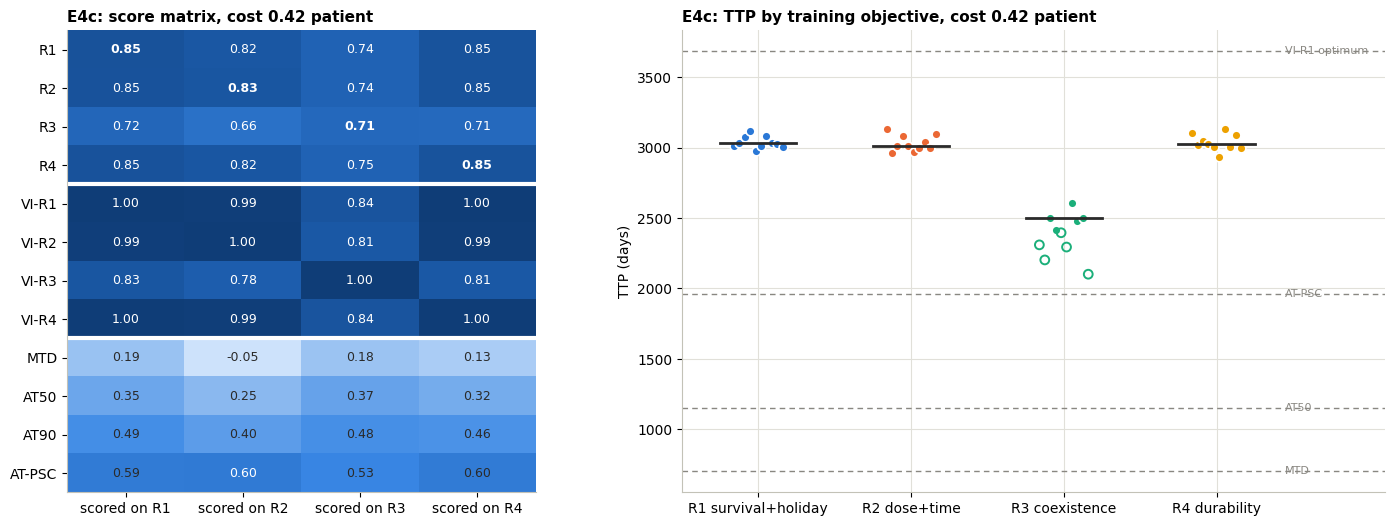

,TTP,dose,dose_pct,mean_fR,term_fR,mean_burden,regrow,f_holiday,G_R1,G_R2,G_R3,G_R4
R1,"3.03e+03 [3.01e+03, 3.07e+03]","2.17e+03 [2.15e+03, 2.19e+03]","71.6 [71.5, 71.6]","0.0992 [0.0978, 0.1]","0.613 [0.61, 0.616]","1.15 [1.15, 1.15]","0.0164 [0.0164, 0.0164]","0.599 [0.596, 0.602]","40.2 [40, 40.6]","-90.7 [-90.8, -90.6]","-75.8 [-75.9, -75.7]","32.2 [32, 32.5]"
R2,"3.01e+03 [3e+03, 3.07e+03]","2.14e+03 [2.14e+03, 2.19e+03]","71.5 [71.4, 71.5]","0.0984 [0.0971, 0.0996]","0.589 [0.584, 0.593]","1.15 [1.15, 1.15]","0.0162 [0.0162, 0.0162]","0.575 [0.57, 0.58]","40.1 [39.9, 40.6]","-90.7 [-90.8, -90.6]","-75.8 [-76, -75.7]","32.1 [31.9, 32.6]"
R3,"2.5e+03 [2.48e+03, 2.5e+03]","1.82e+03 [1.81e+03, 1.82e+03]","72.8 [72.8, 72.9]","0.12 [0.119, 0.12]","0.671 [0.669, 0.673]","1.1 [1.1, 1.11]","0.0169 [0.0169, 0.0169]","0.658 [0.656, 0.66]","34.1 [33.9, 34.1]","-92.6 [-92.7, -92.6]","-77 [-77.1, -76.7]","26.9 [26.7, 26.9]"
R4,"3.02e+03 [3e+03, 3.08e+03]","2.16e+03 [2.14e+03, 2.2e+03]","71.4 [71.3, 71.5]","0.0974 [0.097, 0.099]","0.598 [0.584, 0.605]","1.15 [1.15, 1.15]","0.0163 [0.0162, 0.0163]","0.585 [0.57, 0.591]","40.2 [39.9, 40.7]","-90.7 [-90.7, -90.5]","-75.7 [-75.9, -75.6]","32.2 [32, 32.6]"
None,40.7,0,0,0.000964,0.000926,1.09,0.0125,0.000887,0.649,-101,-100,0.399
MTD,703,703,100,0.512,0.998,0.474,0.0203,0.998,9.43,-101,-94.1,5.21
AT50,1.15e+03,885,76.9,0.21,0.757,0.829,0.0177,0.745,16.8,-97.5,-87.9,12.3
AT90,1.62e+03,1.2e+03,74.5,0.153,0.734,0.976,0.0175,0.722,23.2,-95.7,-84.4,17.8
AT-PSC,1.96e+03,1.34e+03,68.6,0.0749,0.351,1.07,0.0145,0.34,28.1,-93.3,-82.7,22.7
VI-R1,3.68e+03,2.62e+03,71.1,0.09,0.589,1.18,0.0162,0.575,47,-88.7,-72.7,37.9


Cost of the wrong objective (cost 0.42 patient):


,R1,R2,R3,R4
R1,0.000,0.005,-0.036,-0.001
R2,0.004,0.000,-0.036,0.001
R3,0.132,0.166,0.000,0.141
R4,0.001,0.003,-0.038,0.000


,median_a,median_b,diff,mannwhitney_p
pair,,,,
R1 vs R2,3030.853,3008.718,22.135,5.708e-01
R1 vs R3,3030.853,2498.371,532.482,6.660e-04
R1 vs R4,3030.853,3023.515,7.338,9.698e-01
R2 vs R3,3008.718,2498.371,510.347,6.660e-04
R2 vs R4,3008.718,3023.515,-14.796,6.232e-01
R3 vs R4,2498.371,3023.515,-525.144,6.660e-04


In [30]:
crossc = pd.concat([okc.groupby('obj')[cols].agg(miqr),
                    pd.concat([e1c.loc[['None', 'MTD', 'AT50', BEST_ATc, 'AT-PSC'], cols], e2c[cols]]).map(lambda v: f'{v:.3g}')])
crossc.to_csv(f'{RES}/E4c_cross_evaluation.csv')
Mc, LOSSc = score_matrix(okc, e1c, e2c, FLOORc, CEILc, ['MTD', 'AT50', BEST_ATc, 'AT-PSC'])
Mc.to_csv(f'{RES}/E4c_score_matrix.csv')
kwc, pairsc, icc = ttp_tests(okc)
fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1.5], wspace=.25))
plot_score_matrix(axs[0], Mc, 'E4c: score matrix, cost 0.42 patient')
plot_ttp(axs[1], evc, e1c, e2c, BEST_Hc, 'E4c: TTP by training objective, cost 0.42 patient')
save('E4c_cross_evaluation')
SUMMARY['E4c'] = dict(TTP_median={o: round(float(okc[okc.obj == o].TTP.median())) for o in OBJECTIVES},
                      kruskal_p=float(kwc.pvalue), instrumental_convergence_p=float(icc.pvalue),
                      score_matrix=Mc.loc[list(OBJECTIVES)].round(3).to_dict(), loss=LOSSc.round(3).to_dict())
display(crossc)
print('Cost of the wrong objective (cost 0.42 patient):'); display(LOSSc.round(3))
pairsc

shared state set: 14398 states, N/N0 in [0.08, 1.20]


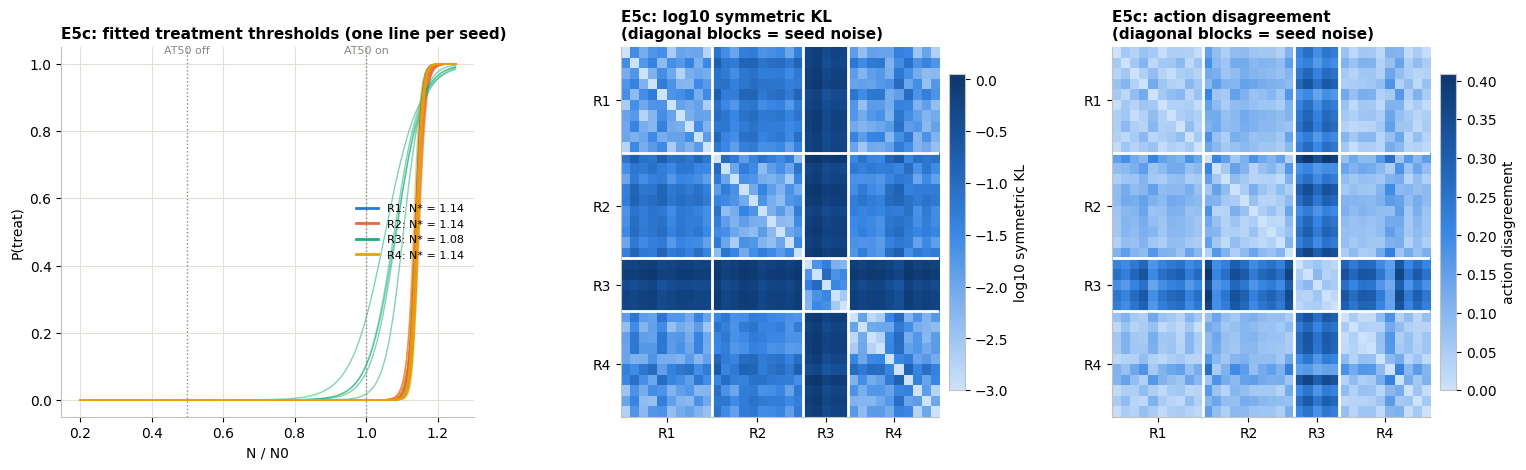

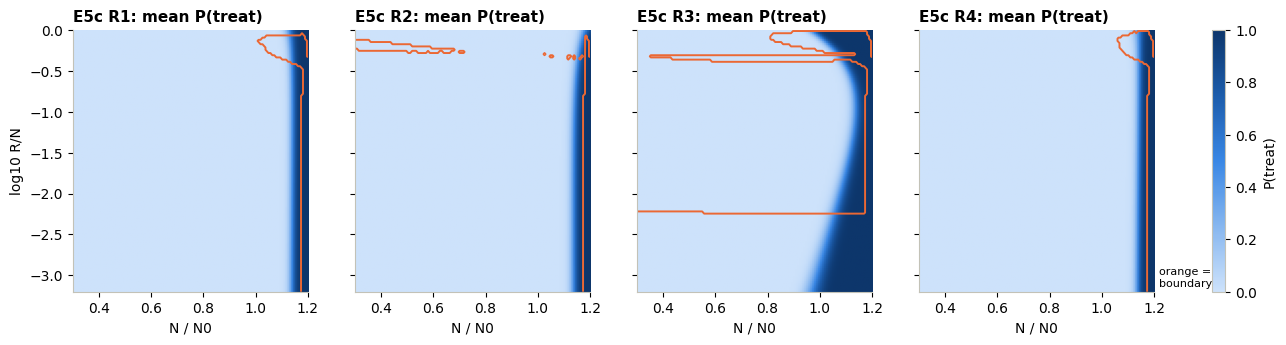

,N_star,slope,R2_burden_only,N_star_95CI
R1,1.141,122.369,0.993,"[1.138, 1.142]"
R2,1.141,94.838,0.926,"[1.138, 1.145]"
R3,1.083,27.394,0.653,"[1.054, 1.104]"
R4,1.142,123.899,0.993,"[1.139, 1.144]"
VI-R1,1.174,169.105,0.347,NaN
VI-R2,1.179,570.689,0.659,NaN
VI-R3,1.174,86.230,0.045,NaN
VI-R4,1.174,199.124,0.395,NaN


,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,0.060,0.019,3.124,5.999e-04,0.099,0.066,5.999e-04,DIFFERENT policies
R1 vs R3,0.596,0.018,33.510,3.999e-04,0.233,0.052,3.999e-04,DIFFERENT policies
R1 vs R4,0.022,0.021,1.056,2.216e-01,0.065,0.063,2.394e-01,not distinguishable from seed noise
R2 vs R3,0.711,0.024,29.299,3.999e-04,0.267,0.074,3.999e-04,DIFFERENT policies
R2 vs R4,0.050,0.025,1.975,5.999e-04,0.096,0.077,6.999e-03,DIFFERENT policies
R3 vs R4,0.644,0.027,23.612,2.000e-04,0.252,0.069,2.000e-04,DIFFERENT policies


TTP (d)           own score              N*         
         PoP  cost .42       PoP cost .42    PoP cost .42
R1  1743.872  3030.853     0.867    0.854  1.144    1.141
R2  1726.106  3008.718     0.848    0.826  1.149    1.141
R3  1493.520  2498.371     0.763    0.702  1.084    1.083
R4  1750.770  3023.515     0.868    0.847  1.146    1.142

,PoP,cost .42,disagree ratio PoP,disagree ratio cost .42
pair,,,,
R1 vs R2,DIFFERENT policies,DIFFERENT policies,2.75,1.48
R1 vs R3,DIFFERENT policies,DIFFERENT policies,3.78,4.47
R1 vs R4,not distinguishable from seed noise,not distinguishable from seed noise,1.10,1.03
R2 vs R3,DIFFERENT policies,DIFFERENT policies,4.84,3.60
R2 vs R4,DIFFERENT policies,DIFFERENT policies,2.12,1.26
R3 vs R4,DIFFERENT policies,DIFFERENT policies,3.71,3.65


In [31]:
PSc = policy_space(PC, AGc, VIPc, BASEc, okc)
SUMMARY['E5c_threshold'] = {k: round(float(v), 3) for k, v in PSc['tab'].N_star.items()}
SUMMARY['E5c_divergence'] = PSc['div'][['between_KL', 'within_KL', 'p_KL', 'between_disagree', 'within_disagree', 'verdict']].round(4).to_dict('index')
plot_divergence(PSc, 'E5c'); save('E5c_policy_divergence')
plot_agent_maps(PC, AGc, okc, VIc, 'E5c'); save('E5c_agent_policy_maps')

side = pd.DataFrame({('TTP (d)', 'PoP'): ok.groupby('obj').TTP.median(), ('TTP (d)', 'cost .42'): okc.groupby('obj').TTP.median(),
                     ('own score', 'PoP'): ev3.groupby('obj').own_score.median(), ('own score', 'cost .42'): evc.groupby('obj').own_score.median(),
                     ('N*', 'PoP'): tab5.N_star.loc[list(OBJECTIVES)], ('N*', 'cost .42'): PSc['tab'].N_star.reindex(list(OBJECTIVES))})
verdicts = pd.DataFrame({'PoP': div.verdict, 'cost .42': PSc['div'].verdict,
                         'disagree ratio PoP': div.between_disagree / div.within_disagree,
                         'disagree ratio cost .42': PSc['div'].between_disagree / PSc['div'].within_disagree})
display(PSc['tab']); display(PSc['div']); display(side.round(3))
verdicts.round(2)

**Reading E3c–E5c.** The PoP results replicate on a patient with a cost of resistance, and durability is the same objective as survival under both of its definitions.
- **The scale changes, the structure does not.** Every TTP is about 1.7× longer: VI-R1 3683 d vs 2038 d, and agents ≈3020 d vs 1744 d. Tuned AT-PSC is now genuinely partial-cycle (21 of 28 days, 1959 d) and is the best heuristic. The agents beat it by about 55%.
- **R4 (resistant fraction after a 180-day holiday) ≡ R1 again.** VI-R4 = VI-R1 on both patients. Containment keeps sensitive cells as abundant as the burden cap allows, and that simultaneously maximises survival and minimises the resistant fraction.
- **Raising the durability weight changes the policy only through a loophole.** At 5× and 10× the weight, TTP drops (PoP 1774 / 1540 d; cost patient 3103 / 2704 d) and the resistant fraction falls. But every episode then ends exactly where 0.1 − w·f reaches zero (f at the end ≈ 0.2 and 0.1 = 0.1/w). The agent contains as before and stops treating once a week of survival would score negatively. **With the progression penalty raised by the D11 rule (`+`), the optimum is exactly containment again at both weights.** The superseded population-growth form behaves the same way: unchanged up to 10×, giving up immediately at 100×.
- **Cross-evaluation.** R1, R2 and R4 agents reach 3009–3031 d and are pairwise indistinguishable. R3 reaches 2498 d (Kruskal–Wallis p = 0.005). Training on R3 costs 0.13–0.17 of the optimum on every other objective; R1, R2 and R4 cost each other ≤ 0.005. They again score *higher on R3's own objective* than R3-trained agents, by 0.036–0.038.
- **R3 is harder to train here.** 5 of 10 seeds fall below 0.7 of the optimum (median 0.70) and are excluded. The budget is the same 10⁶ steps, but episodes are about 1.7× longer. The R3 statistics rest on 5 seeds.
- **Policy space.** The verdicts match PoP: 5 of 6 pairs differ beyond seed noise, and R1 vs R4 is indistinguishable (KL ratio 1.06, p = 0.22). The R1–R2 and R2–R4 differences shrink (disagreement ratio 1.3–1.5, against 2.1–2.7 on PoP). The thresholds are unchanged: N* = 1.14 for R1, R2 and R4, and 1.08 for R3.

**Bottom line:** in this model, durability is not a separate objective. Whether it is measured as resistant regrowth or as the resistant fraction after a holiday, it is optimised by the same containment policy as survival. A larger durability weight only teaches the agent to give up early.

## E11: Burden-only observation (what a clinician actually sees)

Clinically, only a burden proxy such as PSA is measured, not the sensitive/resistant composition. Here the agents see **only N/N₀**: Gallagher's s₁, memoryless, with no history. Everything else matches E3: 4 objectives × 10 seeds on the PoP patient, with the same PPO, budget and seeds. The ceilings are E2's **full-information** VI optima, which a burden-only agent cannot exceed.

Three questions:
1. How much does losing composition cost each objective?
2. Do the objectives still produce different policies?
3. For each objective, does the burden-only policy differ from the full-state one, beyond seed noise?

In [32]:
E11 = run_many(jobs('E11'))
AGb = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E11}
evb = split(evaluate(AGb))
evb['own_score'] = [score(r[f'G_{r.obj}'], r.obj, FLOOR, CEIL) for _, r in evb.iterrows()]
okb = evb[evb.own_score >= 0.7].copy()
print('did not train (< 0.7 of the full-information ceiling):', list(evb.policy[evb.own_score < 0.7]) or 'none')
cmp11 = pd.DataFrame({('TTP (d)', 'full'): ev3.groupby('obj').TTP.median(), ('TTP (d)', 'burden'): evb.groupby('obj').TTP.median(),
                      ('TTP (d)', 'Mann-Whitney p'): [stats.mannwhitneyu(ev3[ev3.obj == o].TTP, evb[evb.obj == o].TTP).pvalue for o in OBJECTIVES],
                      ('own score', 'full'): ev3.groupby('obj').own_score.median(), ('own score', 'burden'): evb.groupby('obj').own_score.median(),
                      ('mean resistant fraction', 'full'): ev3.groupby('obj').mean_fR.median(),
                      ('mean resistant fraction', 'burden'): evb.groupby('obj').mean_fR.median(),
                      ('trained seeds', 'burden'): okb.groupby('obj').size().reindex(list(OBJECTIVES), fill_value=0)})
SUMMARY['E11'] = {o: dict(TTP_full=round(float(cmp11.loc[o, ('TTP (d)', 'full')])), TTP_burden=round(float(cmp11.loc[o, ('TTP (d)', 'burden')])),
                          score_full=round(float(cmp11.loc[o, ('own score', 'full')]), 3), score_burden=round(float(cmp11.loc[o, ('own score', 'burden')]), 3),
                          trained_burden=int(cmp11.loc[o, ('trained seeds', 'burden')])) for o in OBJECTIVES}
cmp11.round(3)

did not train (< 0.7 of the full-information ceiling): ['R1|s0', 'R1|s1', 'R1|s2', 'R1|s3', 'R1|s4', 'R1|s5', 'R1|s6', 'R1|s7', 'R1|s8', 'R1|s9', 'R2|s0', 'R2|s1', 'R2|s2', 'R2|s3', 'R2|s4', 'R2|s5', 'R2|s6', 'R2|s7', 'R2|s8', 'R2|s9', 'R3|s0', 'R3|s1', 'R3|s2', 'R3|s3', 'R3|s4', 'R3|s5', 'R3|s6', 'R3|s7', 'R3|s8', 'R3|s9', 'R4|s0', 'R4|s1', 'R4|s2', 'R4|s3', 'R4|s4', 'R4|s5', 'R4|s6', 'R4|s7', 'R4|s8', 'R4|s9']


TTP (d)                         own score        mean resistant fraction        trained seeds
         full   burden Mann-Whitney p      full burden                    full burden        burden
obj                                                                                                
R1   1743.872  681.669            0.0     0.867  0.332                   0.078  0.188             0
R2   1726.106  768.776            0.0     0.848  0.235                   0.074  0.165             0
R3   1493.520  591.912            0.0     0.763  0.331                   0.095  0.223             0
R4   1750.770  703.287            0.0     0.868  0.317                   0.077  0.182             0

best memoryless burden rule: treat iff N >= 1.17 N0 -> TTP 1945 d, 0.96 of the full-information R1 optimum
thresholds the burden-only agents learned (N*/N0, median [IQR] over seeds):


obj
R1    0.767 [0.742, 0.773]
R2    0.846 [0.841, 0.863]
R3    0.646 [0.584, 0.664]
R4    0.792 [0.765, 0.823]
Name: N_star, dtype: str

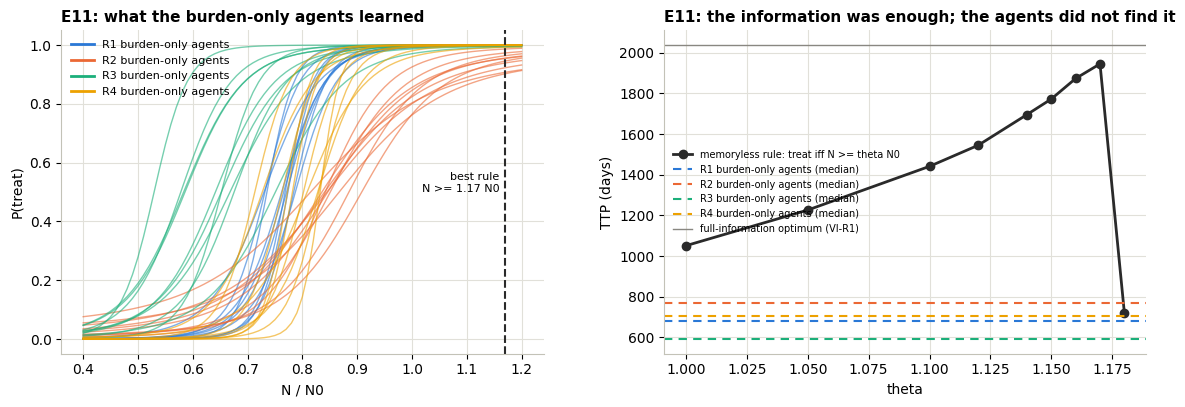

,TTP,G_R1,R1_score
theta,,,
1.00,1050.965,15.599,0.530
1.05,1226.235,18.085,0.618
1.10,1441.043,21.006,0.722
1.12,1544.771,22.475,0.774
1.14,1695.496,24.517,0.846
1.15,1772.122,25.501,0.881
1.16,1873.104,26.786,0.927
1.17,1944.891,27.749,0.961
1.18,720.883,11.380,0.381


In [33]:
# Information limit or learning failure? The best memoryless burden-only RULE uses exactly the agents' information.
rule = pd.DataFrame([dict(theta=th, **{k: v[0] for k, v in rollout(Contain(th), [POP], objs=('R1',)).items() if k in ('TTP', 'G_R1')})
                     for th in (1.0, 1.05, 1.1, 1.12, 1.14, 1.15, 1.16, 1.17, 1.18)]).set_index('theta')
rule['R1_score'] = (rule.G_R1 - FLOOR['R1']) / (CEIL['R1'] - FLOOR['R1'])
xs = np.linspace(.4, 1.2, 81); pB = stack(POP)
ptreat = lambda a: a.probs(xs * POP['N0'] * (1 - POP['fR']), xs * POP['N0'] * POP['fR'], pB)   # burden agents ignore composition
thr11 = split(pd.DataFrame([dict(policy=k, N_star=fit_threshold(xs, ptreat(a))[0]) for k, a in AGb.items()]))
learned = thr11.groupby('obj').N_star.agg(miqr)
best = rule.R1_score.idxmax()
print(f"best memoryless burden rule: treat iff N >= {best} N0 -> TTP {rule.loc[best, 'TTP']:.0f} d, "
      f"{rule.loc[best, 'R1_score']:.2f} of the full-information R1 optimum")
print('thresholds the burden-only agents learned (N*/N0, median [IQR] over seeds):'); display(learned)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(wspace=.25))
for k, a in AGb.items():
    axs[0].plot(xs, ptreat(a), color=COL[k.split('|')[0]], lw=1, alpha=.6)
for o in OBJECTIVES:
    axs[0].plot([], [], color=COL[o], label=f'{o} burden-only agents')
axs[0].axvline(best, color=INK, lw=1.5, ls='--'); axs[0].text(best - .01, .5, f'best rule\nN >= {best} N0', ha='right', fontsize=8)
axs[0].set(xlabel='N / N0', ylabel='P(treat)', title='E11: what the burden-only agents learned')
axs[0].legend(fontsize=8, loc='upper left')
axs[1].plot(rule.index, rule.TTP, 'o-', color=INK, label='memoryless rule: treat iff N >= theta N0')
for o in OBJECTIVES:
    axs[1].axhline(evb[evb.obj == o].TTP.median(), color=COL[o], lw=1.5, ls=(0, (4, 3)), label=f'{o} burden-only agents (median)')
axs[1].axhline(e2.loc['VI-R1', 'TTP'], color=MUTED, lw=1, label='full-information optimum (VI-R1)')
axs[1].set(xlabel='theta', ylabel='TTP (days)', title='E11: the information was enough; the agents did not find it')
axs[1].legend(fontsize=7, loc='center left')
save('E11_burden_diagnosis')
SUMMARY['E11_diagnosis'] = dict(best_rule_theta=float(best), best_rule_TTP=round(float(rule.loc[best, 'TTP'])),
                                best_rule_R1_score=round(float(rule.loc[best, 'R1_score']), 3),
                                agents_N_star={o: round(float(thr11[thr11.obj == o].N_star.median()), 3) for o in OBJECTIVES})
rule.round(3)

In [34]:
ENOUGH = okb.obj.value_counts().ge(2).sum() >= 2   # cross-objective tests need >= 2 objectives with >= 2 trained seeds
if not ENOUGH:
    print('Skipped: too few burden-only agents trained (Phase 2 rule: untrained agents say nothing about their objective).')
else:
    crossb = okb.groupby('obj')[cols].agg(miqr)
    crossb.to_csv(f'{RES}/E11_cross_evaluation.csv')
    Mb, LOSSb = score_matrix(okb, e1, e2, FLOOR, CEIL, ['MTD', 'AT50', BEST_AT, 'AT-PSC'])
    Mb.to_csv(f'{RES}/E11_score_matrix.csv')
    kwb, pairsb, icb = ttp_tests(okb)
    fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1.5], wspace=.25))
    plot_score_matrix(axs[0], Mb, 'E11: score matrix, burden-only agents')
    plot_ttp(axs[1], evb, e1, e2, BEST_H, 'E11: TTP by training objective, burden-only agents')
    save('E11_cross_evaluation')
    SUMMARY['E11_cross'] = dict(kruskal_p=float(kwb.pvalue), score_matrix=Mb.loc[list(OBJECTIVES)].round(3).to_dict(), loss=LOSSb.round(3).to_dict())
    display(crossb)
    print('Cost of the wrong objective (burden-only agents):'); display(LOSSb.round(3))
    pairsb

Skipped: too few burden-only agents trained (Phase 2 rule: untrained agents say nothing about their objective).


In [35]:
if not ENOUGH:
    print('Skipped (see above).')
else:
    PSb = policy_space(POP, AGb, VIP, BASE, okb)                  # do objectives still differ when only burden is seen?
    plot_divergence(PSb, 'E11'); save('E11_policy_divergence')

    AGfb = {f"{k.split('|')[0]}-full|{k.split('|')[1]}": AG3[k] for k in ok.policy}
    AGfb |= {f"{k.split('|')[0]}-burden|{k.split('|')[1]}": AGb[k] for k in okb.policy}
    PSfb = policy_space(POP, AGfb, {}, {}, pd.DataFrame({'policy': list(AGfb)}),
                        pairs=[(f'{o}-full', f'{o}-burden') for o in OBJECTIVES])   # same objective, full vs burden
    SUMMARY['E11_threshold'] = {k: round(float(v), 3) for k, v in PSb['tab'].N_star.items()}
    SUMMARY['E11_divergence'] = PSb['div'][['between_KL', 'within_KL', 'p_KL', 'verdict']].round(4).to_dict('index')
    SUMMARY['E11_full_vs_burden'] = PSfb['div'][['between_KL', 'within_KL', 'between_disagree', 'within_disagree', 'verdict']].round(4).to_dict('index')
    display(PSb['tab']); display(PSb['div'])
    PSfb['div']

Skipped (see above).


**Reading E11.** **Burden-only PPO agents did not train.** Every seed of every objective scores only 0.21–0.37 of the full-information optimum, with TTP 535–863 d, about AT50's level and below the tuned heuristics. Under the Phase 2 rule, the cross-evaluation and policy-space tests are therefore skipped: these agents say nothing about their objectives.

**This is a learning failure, not an information limit.**
- A fixed memoryless rule, *treat iff N ≥ 1.17 N₀*, uses exactly the information the agents had and reaches 1945 d, **0.96 of the full-information R1 optimum**.
- The agents instead converge on much lower thresholds, treating whenever burden exceeds 0.65–0.85 N₀ (median N\* R3 0.65, R1 0.77, R4 0.79, R2 0.85). They do this consistently across seeds, and their training TTP plateaus within the first tenth of training.
- **The good rule sits next to a cliff.** θ = 1.17 gives 1945 d, but θ = 1.18 collapses to 721 d, because one week of untreated growth then crosses 1.2 N₀. A learner that cannot see composition has every reason to stay far from that edge.
- The likely cause is **critic aliasing**. With only N as input, the value of a given burden depends on hidden composition: a high-burden state is safe early in the episode and doomed late. The critic's baseline is therefore biased, and PPO settles on a conservative local optimum. That is the instability Kiram 2026 reports for memoryless agents.

**Clinical reading.** A burden-only biomarker carries enough information for near-optimal containment in this model, but a standard memoryless RL agent does not find it. A transparent threshold rule beats it. Two remedies would keep the deployed policy burden-only:
- an **asymmetric critic** that sees the simulator's full state during training only;
- **memory** (frame-stacking or an LSTM).

## E11b: Burden-only policy, full-state critic (asymmetric actor–critic)

E11 failed because the critic, seeing only N, cannot tell a safe high-burden state from a doomed one. Here the **actor**, the policy that would be deployed, still sees only N/N₀. The **critic** sees the full simulator state, but only during training, and it is discarded at deployment. In silico that is legitimate: the simulator knows the composition even though a clinician would not.

Everything else matches E11 and E3: PoP patient, 4 objectives × 10 seeds, same PPO, budget and seeds, same 0.7 rule against the full-information VI ceilings.

did not train (< 0.7 of the full-information ceiling): none


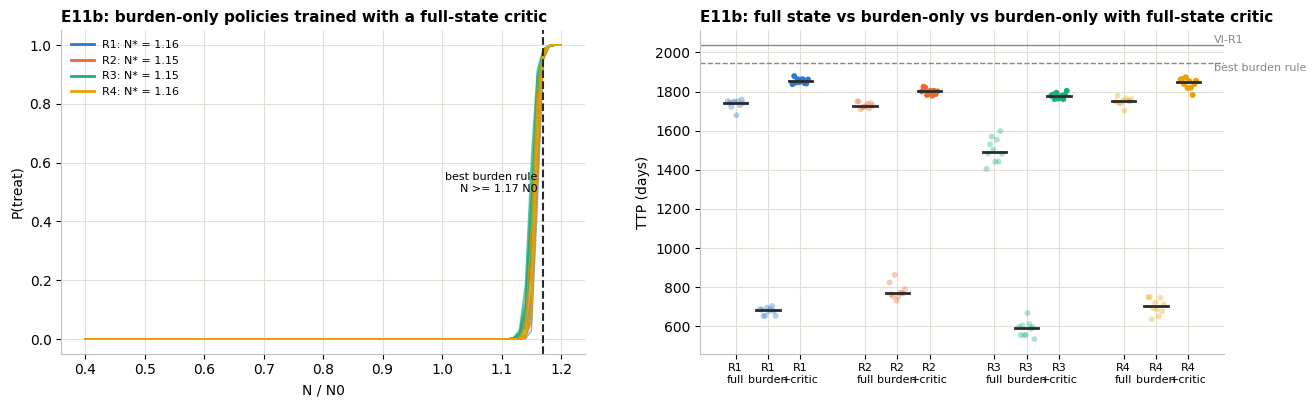

TTP (d)                                own score                                     N*                                  vs full state        trained seeds
   full state   burden burden + full critic full state burden burden + full critic full state burden burden + full critic TTP Mann-Whitney p burden + full critic
R1   1743.872  681.669             1854.800      0.867  0.332                0.919      1.144  0.767                1.158                0.0                   10
R2   1726.106  768.776             1800.809      0.848  0.235                0.860      1.149  0.846                1.153                0.0                   10
R3   1493.520  591.912             1778.500      0.763  0.331                0.798      1.084  0.646                1.151                0.0                   10
R4   1750.770  703.287             1846.266      0.868  0.317                0.914      1.146  0.792                1.157                0.0                   10

In [36]:
E11b = run_many(jobs('E11b'))
AGa = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E11b}
eva = split(evaluate(AGa))
eva['own_score'] = [score(r[f'G_{r.obj}'], r.obj, FLOOR, CEIL) for _, r in eva.iterrows()]
oka = eva[eva.own_score >= 0.7].copy()
print('did not train (< 0.7 of the full-information ceiling):', list(eva.policy[eva.own_score < 0.7]) or 'none')
thra = split(pd.DataFrame([dict(policy=k, N_star=fit_threshold(xs, ptreat(a))[0]) for k, a in AGa.items()]))
V3 = {'full state': ev3, 'burden': evb, 'burden + full critic': eva}
cmp11b = pd.concat({
    'TTP (d)': pd.DataFrame({k: v.groupby('obj').TTP.median() for k, v in V3.items()}),
    'own score': pd.DataFrame({k: v.groupby('obj').own_score.median() for k, v in V3.items()}),
    'N*': pd.DataFrame({'full state': tab5.N_star.loc[list(OBJECTIVES)], 'burden': thr11.groupby('obj').N_star.median(),
                        'burden + full critic': thra.groupby('obj').N_star.median()}),
    'vs full state': pd.DataFrame({'TTP Mann-Whitney p': [stats.mannwhitneyu(ev3[ev3.obj == o].TTP, eva[eva.obj == o].TTP).pvalue
                                                          for o in OBJECTIVES]}, index=list(OBJECTIVES)),
    'trained seeds': pd.DataFrame({'burden + full critic': oka.groupby('obj').size().reindex(list(OBJECTIVES), fill_value=0)})}, axis=1)
SUMMARY['E11b'] = {o: dict(TTP=round(float(eva[eva.obj == o].TTP.median())), score=round(float(eva[eva.obj == o].own_score.median()), 3),
                           N_star=round(float(thra[thra.obj == o].N_star.median()), 3), trained=int((oka.obj == o).sum())) for o in OBJECTIVES}

fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw=dict(wspace=.22))
for k, a in AGa.items():
    axs[0].plot(xs, ptreat(a), color=COL[k.split('|')[0]], lw=1, alpha=.6)
for o in OBJECTIVES:
    axs[0].plot([], [], color=COL[o], label=f'{o}: N* = {thra[thra.obj == o].N_star.median():.2f}')
axs[0].axvline(best, color=INK, lw=1.5, ls='--'); axs[0].text(best - .01, .5, f'best burden rule\nN >= {best} N0', ha='right', fontsize=8)
axs[0].set(xlabel='N / N0', ylabel='P(treat)', title='E11b: burden-only policies trained with a full-state critic')
axs[0].legend(fontsize=8, loc='upper left')
for i, o in enumerate(OBJECTIVES):
    for j, (name, v) in enumerate(V3.items()):
        d = v[v.obj == o].TTP; x = i + (j - 1) * .25
        axs[1].scatter(x + np.linspace(-.06, .06, len(d)), d, s=18, color=COL[o], alpha=(.35, .35, 1)[j], edgecolor='none')
        axs[1].plot([x - .09, x + .09], [d.median()] * 2, color=INK, lw=2)
axs[1].axhline(e2.loc['VI-R1', 'TTP'], color=MUTED, lw=1); axs[1].text(3.45, e2.loc['VI-R1', 'TTP'], 'VI-R1', color=MUTED, fontsize=8, va='bottom')
axs[1].axhline(rule.loc[best, 'TTP'], color=MUTED, lw=1, ls='--')
axs[1].text(3.45, rule.loc[best, 'TTP'], 'best burden rule', color=MUTED, fontsize=8, va='top')
axs[1].set_xticks([i + d for i in range(4) for d in (-.25, 0, .25)], [f'{o}\n{t}' for o in OBJECTIVES for t in ('full', 'burden', '+critic')], fontsize=8)
axs[1].set(ylabel='TTP (days)', title='E11b: full state vs burden-only vs burden-only with full-state critic')
save('E11b_asymmetric_critic')
cmp11b.round(3)

Kruskal-Wallis on TTP across objectives: H = 27.89, p = 3.8e-06
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


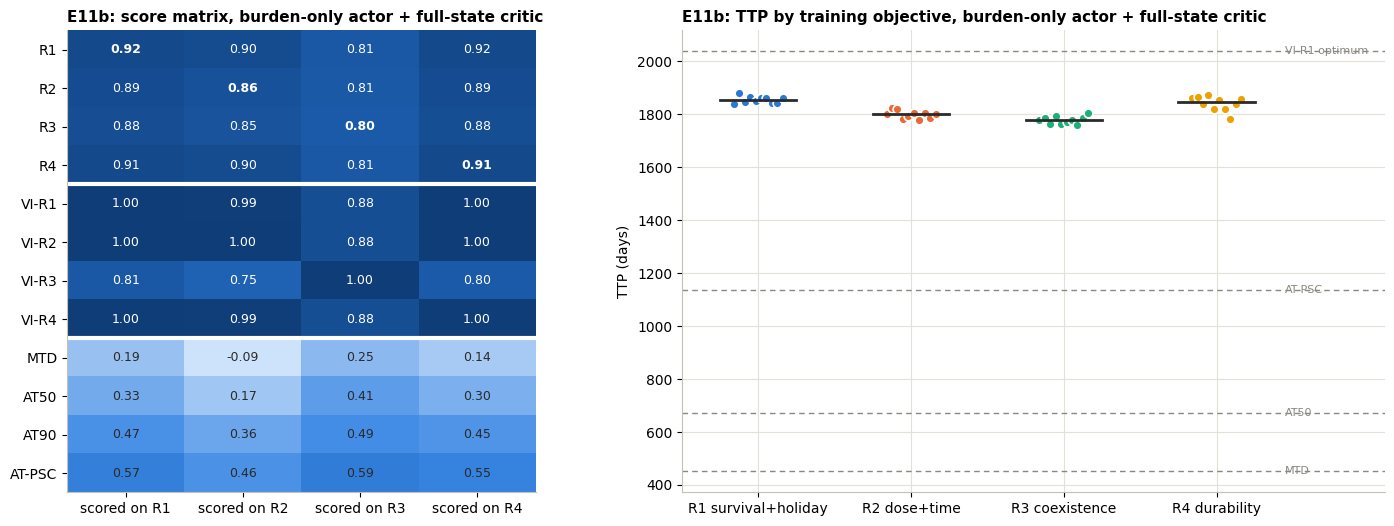

,TTP,dose,dose_pct,mean_fR,term_fR,mean_burden,regrow,f_holiday,G_R1,G_R2,G_R3,G_R4
obj,,,,,,,,,,,,
R1,"1.85e+03 [1.84e+03, 1.86e+03]","1.33e+03 [1.32e+03, 1.34e+03]","71.7 [71.5, 71.8]","0.0744 [0.0725, 0.0751]","0.448 [0.43, 0.454]","1.17 [1.17, 1.17]","0.0215 [0.0215, 0.0215]","0.448 [0.43, 0.454]","26.6 [26.4, 26.6]","-94.3 [-94.3, -94.3]","-84.2 [-84.3, -84.2]","21.6 [21.5, 21.6]"
R2,"1.8e+03 [1.79e+03, 1.8e+03]","1.29e+03 [1.29e+03, 1.3e+03]","71.9 [71.7, 72]","0.0764 [0.0749, 0.0774]","0.452 [0.441, 0.465]","1.16 [1.16, 1.16]","0.0215 [0.0215, 0.0215]","0.452 [0.441, 0.465]","25.9 [25.7, 25.9]","-94.6 [-94.6, -94.5]","-84.4 [-84.4, -84.4]","21 [20.9, 21]"
R3,"1.78e+03 [1.77e+03, 1.78e+03]","1.28e+03 [1.27e+03, 1.29e+03]","72 [71.7, 72.1]","0.0775 [0.0751, 0.0786]","0.46 [0.441, 0.472]","1.16 [1.16, 1.16]","0.0215 [0.0215, 0.0215]","0.46 [0.441, 0.472]","25.6 [25.4, 25.6]","-94.6 [-94.6, -94.6]","-84.5 [-84.7, -84.5]","20.7 [20.6, 20.7]"
R4,"1.85e+03 [1.82e+03, 1.86e+03]","1.32e+03 [1.31e+03, 1.33e+03]","71.7 [71.6, 71.8]","0.0746 [0.0735, 0.0754]","0.445 [0.439, 0.454]","1.17 [1.16, 1.17]","0.0215 [0.0215, 0.0215]","0.445 [0.439, 0.454]","26.4 [26.1, 26.6]","-94.3 [-94.4, -94.3]","-84.3 [-84.4, -84.2]","21.5 [21.3, 21.6]"


Cost of the wrong objective (burden-only actor + full-state critic):


,R1,R2,R3,R4
R1,0.000,-0.036,-0.015,-0.004
R2,0.025,0.000,-0.007,0.023
R3,0.035,0.012,0.000,0.034
R4,0.004,-0.035,-0.013,0.000


,median_a,median_b,diff,mannwhitney_p
pair,,,,
R1 vs R2,1854.800,1800.809,53.992,1.796e-04
R1 vs R3,1854.800,1778.500,76.301,1.796e-04
R1 vs R4,1854.800,1846.266,8.534,2.890e-01
R2 vs R3,1800.809,1778.500,22.309,7.132e-03
R2 vs R4,1800.809,1846.266,-45.458,4.525e-03
R3 vs R4,1778.500,1846.266,-67.766,5.773e-04


In [37]:
ENOUGHa = oka.obj.value_counts().ge(2).sum() >= 2
if not ENOUGHa:
    print('Skipped: too few asymmetric-critic agents trained.')
else:
    crossa = oka.groupby('obj')[cols].agg(miqr)
    crossa.to_csv(f'{RES}/E11b_cross_evaluation.csv')
    Ma, LOSSa = score_matrix(oka, e1, e2, FLOOR, CEIL, ['MTD', 'AT50', BEST_AT, 'AT-PSC'])
    Ma.to_csv(f'{RES}/E11b_score_matrix.csv')
    kwa, pairsa, ica = ttp_tests(oka)
    fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1.5], wspace=.25))
    plot_score_matrix(axs[0], Ma, 'E11b: score matrix, burden-only actor + full-state critic')
    plot_ttp(axs[1], eva, e1, e2, BEST_H, 'E11b: TTP by training objective, burden-only actor + full-state critic')
    save('E11b_cross_evaluation')
    SUMMARY['E11b_cross'] = dict(TTP_median={o: round(float(oka[oka.obj == o].TTP.median())) for o in OBJECTIVES},
                                 kruskal_p=float(kwa.pvalue), instrumental_convergence_p=float(ica.pvalue),
                                 score_matrix=Ma.loc[list(OBJECTIVES)].round(3).to_dict(), loss=LOSSa.round(3).to_dict())
    display(crossa)
    print('Cost of the wrong objective (burden-only actor + full-state critic):'); display(LOSSa.round(3))
    display(pairsa)

shared state set: 6487 states, N/N0 in [0.19, 1.20]


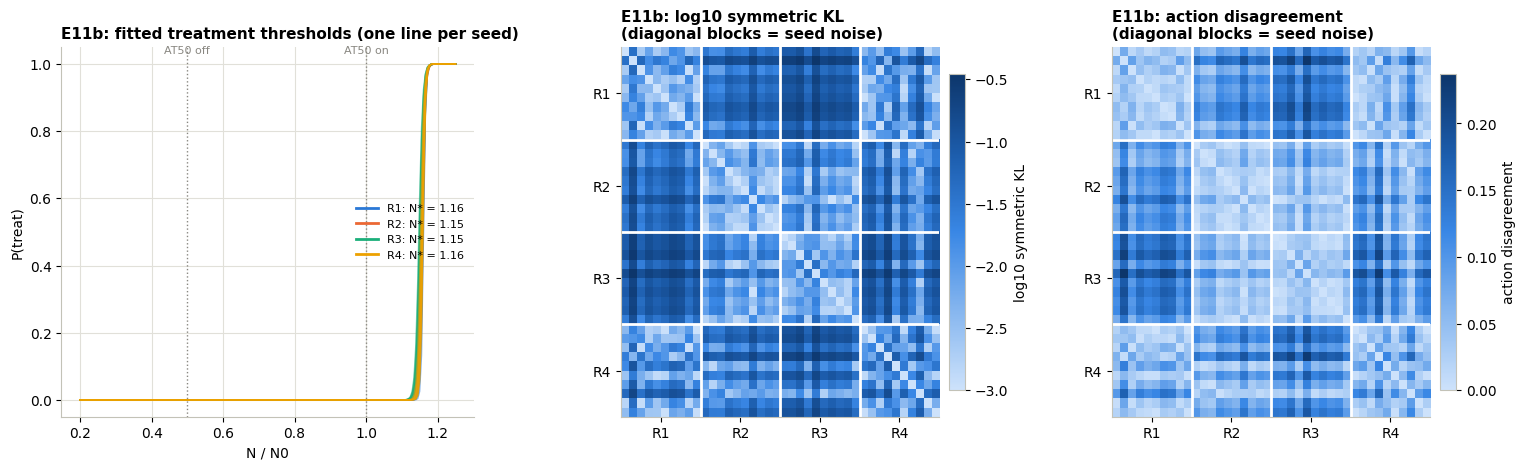

shared state set: 11207 states, N/N0 in [0.98, 1.20]


,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,0.059,0.008,7.182,5.999e-04,0.099,0.030,5.999e-04,DIFFERENT policies
R1 vs R3,0.114,0.010,11.128,5.999e-04,0.139,0.033,5.999e-04,DIFFERENT policies
R1 vs R4,0.021,0.018,1.154,1.338e-01,0.047,0.045,2.332e-01,not distinguishable from seed noise
R2 vs R3,0.016,0.008,2.122,3.999e-03,0.044,0.029,5.999e-03,DIFFERENT policies
R2 vs R4,0.040,0.016,2.540,2.400e-03,0.076,0.041,2.000e-03,DIFFERENT policies
R3 vs R4,0.081,0.018,4.587,7.998e-04,0.112,0.044,7.998e-04,DIFFERENT policies


,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1-full vs R1-burden,0.351,0.011,31.478,5.999e-04,0.253,0.039,5.999e-04,DIFFERENT policies
R2-full vs R2-burden,0.141,0.011,13.092,5.999e-04,0.152,0.043,5.999e-04,DIFFERENT policies
R3-full vs R3-burden,0.813,0.030,26.821,5.999e-04,0.271,0.047,5.999e-04,DIFFERENT policies
R4-full vs R4-burden,0.219,0.026,8.424,5.999e-04,0.191,0.060,5.999e-04,DIFFERENT policies


In [38]:
if not ENOUGHa:
    print('Skipped (see above).')
else:
    PSa = policy_space(POP, AGa, VIP, BASE, oka)                  # do objectives still differ with a burden-only policy?
    plot_divergence(PSa, 'E11b'); save('E11b_policy_divergence')
    AGfa = {f"{k.split('|')[0]}-full|{k.split('|')[1]}": AG3[k] for k in ok.policy}
    AGfa |= {f"{k.split('|')[0]}-burden|{k.split('|')[1]}": AGa[k] for k in oka.policy}
    PSfa = policy_space(POP, AGfa, {}, {}, pd.DataFrame({'policy': list(AGfa)}),
                        pairs=[(f'{o}-full', f'{o}-burden') for o in OBJECTIVES])   # same objective: full state vs burden-only
    SUMMARY['E11b_divergence'] = PSa['div'][['between_KL', 'within_KL', 'p_KL', 'between_disagree', 'within_disagree', 'verdict']].round(4).to_dict('index')
    SUMMARY['E11b_full_vs_burden'] = PSfa['div'][['between_KL', 'within_KL', 'between_disagree', 'within_disagree', 'verdict']].round(4).to_dict('index')
    display(PSa['div'])
    display(PSfa['div'])

**Reading E11b.** The asymmetric critic fixes E11 completely, and the result reframes the main comparison.
- **All 40 agents trained, and burden-only policies now beat the full-state agents for every objective.** TTP is R1 1855 / R2 1801 / R3 1779 / R4 1846 d, against 1744 / 1726 / 1494 / 1751 d for full state (Mann–Whitney p < 10⁻³ for each). Scores are 0.80–0.92 against 0.76–0.87. R1 reaches 0.92 of the full-information optimum, close to the best burden rule's 0.96. That confirms E11's diagnosis: the problem was the critic, not the information.
- **Why burden-only can beat full state.** Every learned policy is one sharp threshold at N\* ≈ 1.15–1.16. That is closer to the optimum's 1.17 than the full-state agents' 1.14. A one-dimensional policy is easier to optimise, and for R1, R2 and R4 the composition inputs barely matter (E5: burden alone explains R² ≈ 0.98).
- **The objective effect shrinks sharply.** A burden-only R3 cannot act on composition, so its early "escape the boundary penalty" treatment is impossible and it is pushed into containment.
  - R3's TTP rises by 285 d, and the R1–R3 gap falls from 250 d to 76 d.
  - The cost of the wrong objective falls from 0.12–0.18 to at most 0.035, and some entries are negative.
  - Policies still differ beyond seed noise for 5 of 6 pairs (R1 ≡ R4 again), but they disagree on only 4–14% of states, against 13–33% with full state.
- **Same objective, full state vs burden-only.** The policies differ in every case: 15–27% disagreement, against ≤ 6% seed noise. *The observation changes the policy more than the objective does.*

**Bottom line:** what the agent can observe matters more than what it is told to optimise. Most of the objective effect in E4/E5, and essentially all of R3's distinctiveness, depends on composition information a clinician does not have. With a clinically realistic burden-only policy, the four objectives converge on nearly the same containment threshold, and the remaining differences are a few percent.

## E11c: Burden-only policy with memory (+ full-state critic)

E11b showed that a burden-only policy nearly erases the objective effect, because it cannot act on composition. A clinician, however, sees a burden *history*, and how burden responds to dosing reveals composition: with mostly sensitive cells, treatment shrinks the tumour; with mostly resistant cells, it does not.

Here the **actor** sees the last 8 weekly burden readings and the last 8 dose decisions, about two months of chart (frame-stacking, the reference doc's s₃). The critic sees the full state during training only, as in E11b. So **memory is the only change from E11b**.

The question: does R3's distinctive early treatment, and with it the objective effect, come back when composition is *inferable* rather than observed?

did not train (< 0.7 of the full-information ceiling): ['R3|s1', 'R3|s2', 'R3|s7', 'R3|s8']


R1 - R3 TTP gap (days): {'full state': 250.0, 'burden': 90.0, 'burden + critic': 76.0, 'burden history + critic': 220.0}


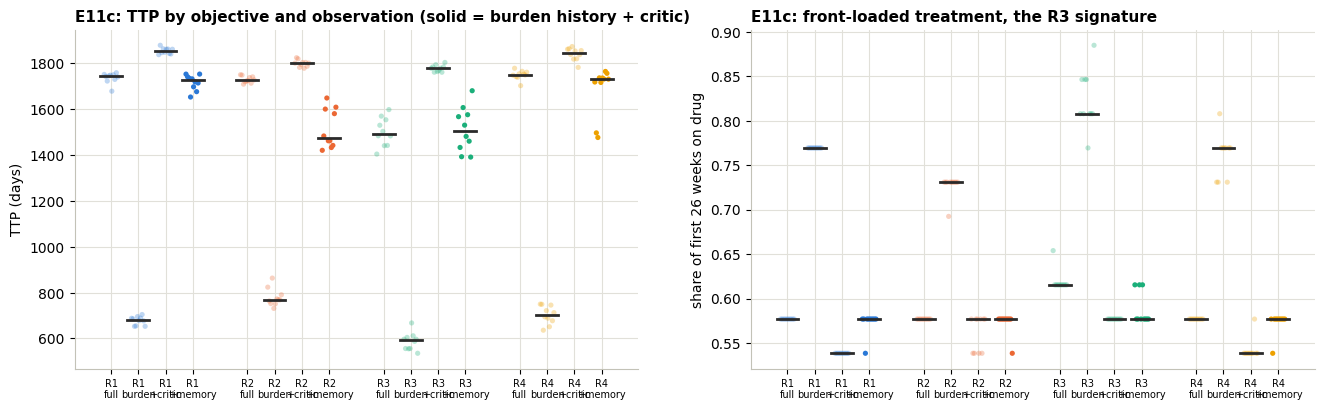

TTP (d)                                                   own score                                                on drug, first 26 wk                                                mean resistant fraction  \
    full state   burden burden + critic burden history + critic full state burden burden + critic burden history + critic           full state burden burden + critic burden history + critic              full state   
obj                                                                                                                                                                                                                     
R1    1743.872  681.669        1854.800                1725.653      0.867  0.332           0.919                   0.859                0.577  0.769           0.538                   0.577                   0.078   
R2    1726.106  768.776        1800.809                1472.788      0.848  0.235           0.860                   0.818                0.577  0.731           0.577                   0.577                   0.074   
R3    1493.520  591.912        1778.500                1505.849      0.763  0.331           0.798                   0.710                0.615  0.808           0.577                   0.577                   0.095   
R4    1750.770  703.287        1846.266                1731.222      0.868  0.317           0.914                   0.859                0.577  0.769           0.538                   0.577                   0.077   

                                                             trained seeds  
    burden burden + critic burden history + critic burden history + critic  
obj                                                                         
R1   0.188           0.074                   0.077                      10  
R2   0.165           0.076                   0.039                      10  
R3   0.223           0.077                   0.054                       6  
R4   0.182           0.075                   0.076                      10

In [39]:
E11c = run_many(jobs('E11c'))
AGm = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E11c}
evm = split(evaluate(AGm))
evm['own_score'] = [score(r[f'G_{r.obj}'], r.obj, FLOOR, CEIL) for _, r in evm.iterrows()]
okm = evm[evm.own_score >= 0.7].copy()
print('did not train (< 0.7 of the full-information ceiling):', list(evm.policy[evm.own_score < 0.7]) or 'none')


def early_dose(agents, weeks=26):
    # share of the first `weeks` decisions spent on drug - R3's signature is front-loaded treatment
    return {k: rollout(a, [POP], record=True, objs=())['traj']['D'][:weeks, 0].mean() for k, a in agents.items()}


V4 = {'full state': (ev3, AG3), 'burden': (evb, AGb), 'burden + critic': (eva, AGa), 'burden history + critic': (evm, AGm)}
for ev, ag in V4.values():
    ev['early_dose'] = ev.policy.map(early_dose(ag))
med = lambda col: pd.DataFrame({k: v.groupby('obj')[col].median() for k, (v, _) in V4.items()})
cmp11c = pd.concat({'TTP (d)': med('TTP'), 'own score': med('own_score'), 'on drug, first 26 wk': med('early_dose'),
                    'mean resistant fraction': med('mean_fR'),
                    'trained seeds': pd.DataFrame({'burden history + critic': okm.groupby('obj').size().reindex(list(OBJECTIVES), fill_value=0)})},
                   axis=1)
gap = (med('TTP').loc['R1'] - med('TTP').loc['R3']).round(0)
print('R1 - R3 TTP gap (days):', gap.to_dict())
SUMMARY['E11c'] = {o: dict(TTP=round(float(evm[evm.obj == o].TTP.median())), score=round(float(evm[evm.obj == o].own_score.median()), 3),
                           early_dose=round(float(evm[evm.obj == o].early_dose.median()), 3), trained=int((okm.obj == o).sum()))
                   for o in OBJECTIVES}
SUMMARY['E11c_R1_R3_gap'] = {k: float(v) for k, v in gap.items()}

fig, axs = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw=dict(wspace=.2))
labels = ('full', 'burden', '+critic', '+memory')
for ax, col, ylab in ((axs[0], 'TTP', 'TTP (days)'), (axs[1], 'early_dose', 'share of first 26 weeks on drug')):
    for i, o in enumerate(OBJECTIVES):
        for j, (v, _) in enumerate(V4.values()):
            d = v[v.obj == o][col]; x = i + (j - 1.5) * .2
            ax.scatter(x + np.linspace(-.05, .05, len(d)), d, s=14, color=COL[o], alpha=(.3, .3, .3, 1)[j], edgecolor='none')
            ax.plot([x - .08, x + .08], [d.median()] * 2, color=INK, lw=2)
    ax.set_xticks([i + (j - 1.5) * .2 for i in range(4) for j in range(4)], [f'{o}\n{l}' for o in OBJECTIVES for l in labels], fontsize=7)
    ax.set_ylabel(ylab)
axs[0].set_title('E11c: TTP by objective and observation (solid = burden history + critic)')
axs[1].set_title('E11c: front-loaded treatment, the R3 signature')
save('E11c_memory')
cmp11c.round(3)

Kruskal-Wallis on TTP across objectives: H = 19.99, p = 0.00017
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


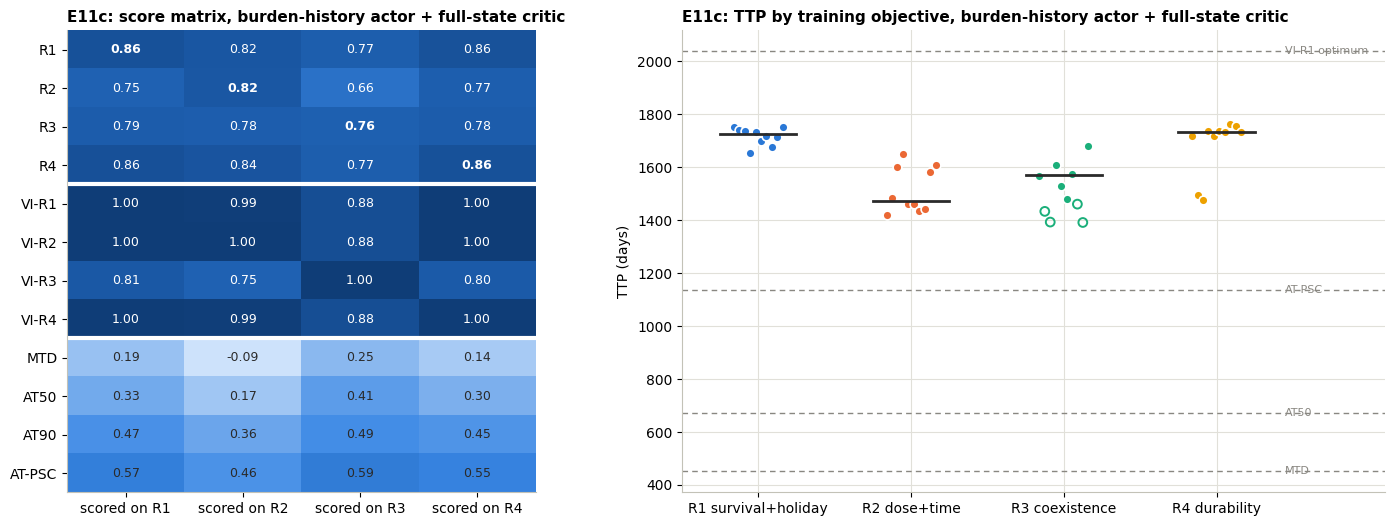

Cost of the wrong objective (burden-history actor):


,R1,R2,R3,R4
R1,0.000,-0.006,-0.013,0.004
R2,0.105,0.000,0.103,0.089
R3,0.073,0.043,0.000,0.076
R4,-0.003,-0.018,-0.012,0.000


,median_a,median_b,diff,mannwhitney_p
pair,,,,
R1 vs R2,1725.653,1472.788,252.865,1.827e-04
R1 vs R3,1725.653,1571.604,154.048,9.990e-04
R1 vs R4,1725.653,1731.222,-5.569,9.097e-01
R2 vs R3,1472.788,1571.604,-98.817,2.635e-01
R2 vs R4,1472.788,1731.222,-258.434,2.202e-03
R3 vs R4,1571.604,1731.222,-159.617,4.196e-02


Cost of the wrong objective, largest off-diagonal entry per observation: {'full state': 0.176, 'burden + critic': 0.035, 'burden history + critic': 0.105}


In [40]:
ENOUGHm = okm.obj.value_counts().ge(2).sum() >= 2
if not ENOUGHm:
    print('Skipped: too few memory agents trained.')
else:
    crossm = okm.groupby('obj')[cols].agg(miqr)
    crossm.to_csv(f'{RES}/E11c_cross_evaluation.csv')
    Mm, LOSSm = score_matrix(okm, e1, e2, FLOOR, CEIL, ['MTD', 'AT50', BEST_AT, 'AT-PSC'])
    Mm.to_csv(f'{RES}/E11c_score_matrix.csv')
    kwm, pairsm, icm = ttp_tests(okm)
    fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1.5], wspace=.25))
    plot_score_matrix(axs[0], Mm, 'E11c: score matrix, burden-history actor + full-state critic')
    plot_ttp(axs[1], evm, e1, e2, BEST_H, 'E11c: TTP by training objective, burden-history actor + full-state critic')
    save('E11c_cross_evaluation')
    SUMMARY['E11c_cross'] = dict(TTP_median={o: round(float(okm[okm.obj == o].TTP.median())) for o in OBJECTIVES},
                                 kruskal_p=float(kwm.pvalue), instrumental_convergence_p=float(icm.pvalue),
                                 score_matrix=Mm.loc[list(OBJECTIVES)].round(3).to_dict(), loss=LOSSm.round(3).to_dict())
    print('Cost of the wrong objective (burden-history actor):'); display(LOSSm.round(3))
    display(pairsm)
    print('Cost of the wrong objective, largest off-diagonal entry per observation:',
          {k: round(float(L.values.max()), 3) for k, L in (('full state', LOSS), ('burden + critic', LOSSa), ('burden history + critic', LOSSm))})

shared history set: 14188 distinct 8-week charts


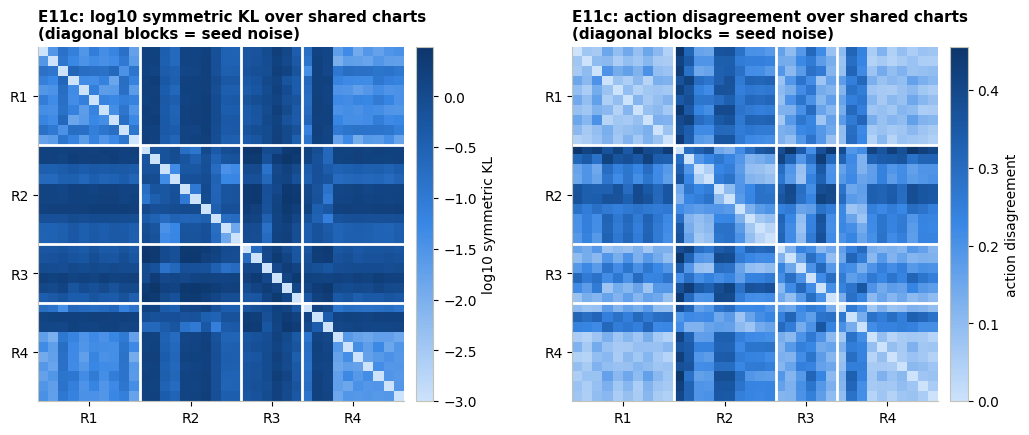

,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,1.061,0.296,3.582,5.999e-04,0.294,0.146,5.999e-04,DIFFERENT policies
R1 vs R3,0.881,0.388,2.271,2.000e-04,0.172,0.123,5.999e-04,DIFFERENT policies
R1 vs R4,0.358,0.312,1.149,3.599e-02,0.126,0.120,1.224e-01,not distinguishable from seed noise
R2 vs R3,1.516,0.708,2.142,3.999e-04,0.276,0.195,2.599e-03,DIFFERENT policies
R2 vs R4,0.865,0.525,1.648,5.999e-03,0.251,0.168,5.999e-04,DIFFERENT policies
R3 vs R4,1.074,0.731,1.470,1.480e-02,0.192,0.157,2.799e-02,not distinguishable from seed noise


between-objective disagreement as a multiple of seed noise, by observation:


,full state,burden + critic,burden history + critic
pair,,,
R1 vs R2,2.75,3.27,2.01
R1 vs R3,3.78,4.23,1.39
R1 vs R4,1.10,1.03,1.05
R2 vs R3,4.84,1.51,1.41
R2 vs R4,2.12,1.84,1.49
R3 vs R4,3.71,2.54,1.22


In [41]:
def history_space(agents, ok, trajs):
    # shared history set: every 8-week chart seen along the reference trajectories (a memory policy has no P(treat | state))
    H = np.unique(np.round(np.concatenate([history_features((t['S'][:, 0] + t['R'][:, 0]) / POP['N0'], t['D'][:, 0]) for t in trajs]), 5), axis=0)
    keys = list(ok.policy); lab = np.array([k.split('|')[0] for k in keys]); Pm = np.array([agents[k].probs_x(H) for k in keys])
    n = len(keys); KL = np.zeros((n, n)); DIS = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            KL[i, j] = KL[j, i] = sym_kl(Pm[i], Pm[j])
            DIS[i, j] = DIS[j, i] = np.mean((Pm[i] > .5) != (Pm[j] > .5))
    div = []
    for a, b in itertools.combinations(OBJECTIVES, 2):
        if min((lab == a).sum(), (lab == b).sum()) < 2:
            continue
        bk, wk, pk = perm_test(KL, lab, a, b); bd, wd, pd_ = perm_test(DIS, lab, a, b)
        div.append(dict(pair=f'{a} vs {b}', between_KL=bk, within_KL=wk, ratio=bk / max(wk, 1e-12), p_KL=pk,
                        between_disagree=bd, within_disagree=wd, p_disagree=pd_,
                        verdict='DIFFERENT policies' if pk < ALPHA and pd_ < ALPHA else 'not distinguishable from seed noise'))
    print(f'shared history set: {len(H)} distinct 8-week charts')
    return dict(KL=KL, DIS=DIS, lab=lab, div=pd.DataFrame(div).set_index('pair'))


def plot_history_divergence(ps, prefix):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw=dict(wspace=.35))
    lab = ps['lab']
    for ax, D, name in ((axs[0], np.log10(ps['KL'] + 1e-3), 'log10 symmetric KL'), (axs[1], ps['DIS'], 'action disagreement')):
        im = ax.imshow(D, cmap=BLUES, aspect='auto'); fig.colorbar(im, ax=ax, label=name, fraction=.046, pad=.03)
        for e in np.cumsum([np.sum(lab == o) for o in OBJECTIVES])[:-1] - .5:
            ax.axhline(e, color='white', lw=2); ax.axvline(e, color='white', lw=2)
        mids = [np.mean(np.where(lab == o)[0]) for o in OBJECTIVES]
        ax.set_xticks(mids, OBJECTIVES); ax.set_yticks(mids, OBJECTIVES); ax.grid(False)
        ax.set_title(f'{prefix}: {name} over shared charts\n(diagonal blocks = seed noise)')


if not ENOUGHm:
    print('Skipped (see above).')
else:
    trajs = [rollout(a, [POP], record=True, objs=())['traj'] for a in list(AGm.values()) + list(AGa.values()) + list(BASE.values())]
    PSm = history_space(AGm, okm, trajs)
    plot_history_divergence(PSm, 'E11c'); save('E11c_policy_divergence')
    cmpdiv = pd.DataFrame({'full state': div.between_disagree / div.within_disagree,
                           'burden + critic': PSa['div'].between_disagree / PSa['div'].within_disagree,
                           'burden history + critic': PSm['div'].between_disagree / PSm['div'].within_disagree}).round(2)
    SUMMARY['E11c_divergence'] = PSm['div'][['between_KL', 'within_KL', 'p_KL', 'between_disagree', 'within_disagree', 'verdict']].round(4).to_dict('index')
    display(PSm['div'])
    print('between-objective disagreement as a multiple of seed noise, by observation:')
    display(cmpdiv)

**Reading E11c.** Memory brings part of the objective effect back, but less cleanly and not through the same mechanism.
- **Learning gets harder again.** Scores fall to 0.71–0.86 (E11b: 0.80–0.92), and 4 of 10 R3 seeds fall below 0.7. Seed-to-seed policy noise roughly quadruples: within-objective disagreement over shared charts is 12–20%, against 3–5% in E11b. Sixteen inputs are harder to learn from than one, even with a full-state critic.
- **Outcome gaps return.** The R1–R3 TTP gap is 220 d (full state 250, burden-only 76). The largest cost of the wrong objective is 0.105 (full state 0.176, burden-only 0.035). R1 ≡ R4 again (5.6 d apart, p = 0.91).
- **But R3's mechanism does not come back.** Its signature front-loaded treatment (share of the first 26 weeks on drug) is 0.58, the same as every other objective. Only 3 of 10 R3 seeds recover the full-state value of 0.62. R3 still progresses earlier, by a route the chart alone does not reveal.
- **R2 becomes the largest outlier, and that is a learning artefact.** R2 agents use 20% less drug (994 vs 1242 days) and progress 15% sooner (1473 d). Yet they score *slightly lower on R2's own objective* than R1-trained agents (G_R2 −94.85 vs −94.81). R2 is calibrated at indifference between a week of dose and a week of survival (decisions D11), so its objective is nearly flat. When learning is harder, agents settle on a dose-sparing policy that is no better for R2 and much worse for survival.
- **Policy space.** Over 14,188 shared 8-week charts, 4 of 6 pairs differ beyond seed noise (R1 ≡ R4, and now R3 ≈ R4). The ratios are only 1.05–2.0, because seed noise is so much larger.

**Bottom line:** with a clinically realistic chart, objectives can matter again. But how much they matter, and which objective stands out, depends as much on how hard each objective is to learn under partial observability as on what it rewards. The results that hold across all four observation settings are narrower:
- R1 ≡ R4;
- R3 never beats R1;
- the cost of the wrong objective depends strongly on what the agent sees (0.18 / 0.035 / 0.105).

## E11d: Memory agents with 3× the training budget

E11c's memory agents learned less well than E11b's memoryless ones: lower scores, failed R3 seeds and about 4× the seed noise. That may be because 16 inputs are harder to learn from in the same 10⁶ steps. Here the **identical** memory setup trains for **3×10⁶ steps**, the same for all four objectives.

Only the memory agents get the larger budget. The comparison that answers the question is **E11c vs E11d**; cross-setting comparisons now also differ in budget.

did not train (< 0.7 of the full-information ceiling): ['R3|s3', 'R3|s6']
R1 - R3 TTP gap (days): {'history 1M (E11c)': 220.0, 'history 3M (E11d)': 235.0, 'burden + critic 1M (E11b)': 76.0, 'full state 1M (E3)': 250.0}


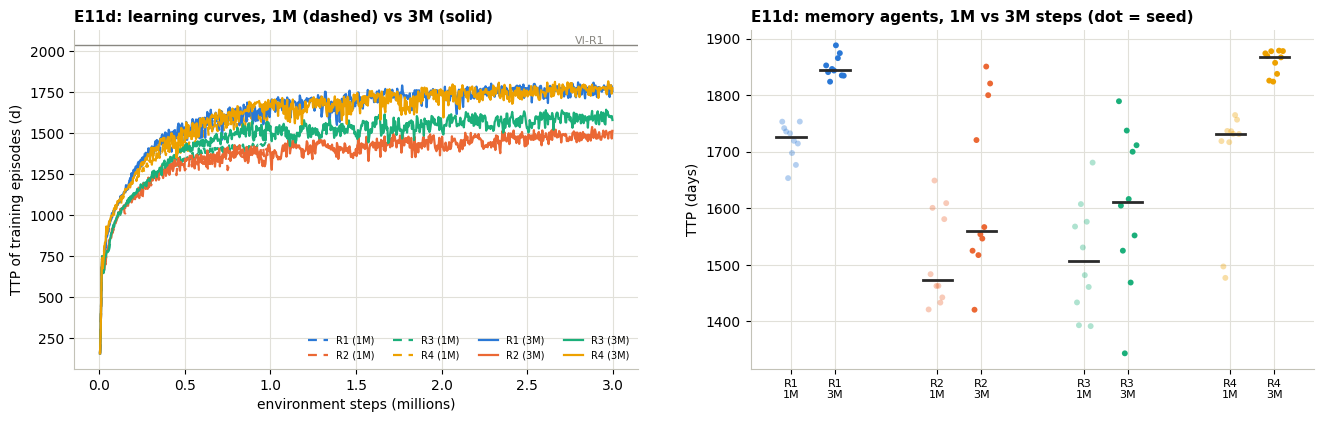

TTP (d)                                                                        own score                                                                cumulative dose (d)                    \
    history 1M (E11c) history 3M (E11d) burden + critic 1M (E11b) full state 1M (E3) history 1M (E11c) history 3M (E11d) burden + critic 1M (E11b) full state 1M (E3)   history 1M (E11c) history 3M (E11d)   
obj                                                                                                                                                                                                           
R1           1725.653          1844.775                  1854.800           1743.872             0.859             0.915                     0.919              0.867            1241.828          1325.982   
R2           1472.788          1560.019                  1800.809           1726.106             0.818             0.872                     0.860              0.848             994.000          1050.000   
R3           1505.849          1610.225                  1778.500           1493.520             0.710             0.803                     0.798              0.763            1039.500          1162.225   
R4           1731.222          1867.899                  1846.266           1750.770             0.859             0.922                     0.914              0.868            1240.271          1342.899   

                                                 on drug, first 26 wk                                                                    trained seeds                                                                 
    burden + critic 1M (E11b) full state 1M (E3)    history 1M (E11c) history 3M (E11d) burden + critic 1M (E11b) full state 1M (E3) history 1M (E11c) history 3M (E11d) burden + critic 1M (E11b) full state 1M (E3)  
obj                                                                                                                                                                                                                    
R1                   1329.399           1256.289                0.577             0.538                     0.538              0.577                10                10                        10                 10  
R2                   1292.879           1238.437                0.577             0.538                     0.577              0.577                10                10                        10                 10  
R3                   1281.500           1098.020                0.577             0.577                     0.577              0.615                 6                 8                        10                 10  
R4                   1324.766           1260.770                0.577             0.538                     0.538              0.577                10                10                        10                 10

In [42]:
E11d = run_many(jobs('E11d'))
AGd = {f"{r['obj']}|s{r['seed']}": Agent(r) for r in E11d}
evd = split(evaluate(AGd))
evd['own_score'] = [score(r[f'G_{r.obj}'], r.obj, FLOOR, CEIL) for _, r in evd.iterrows()]
evd['early_dose'] = evd.policy.map(early_dose(AGd))
okd = evd[evd.own_score >= 0.7].copy()
print('did not train (< 0.7 of the full-information ceiling):', list(evd.policy[evd.own_score < 0.7]) or 'none')

V5 = {'history 1M (E11c)': evm, 'history 3M (E11d)': evd, 'burden + critic 1M (E11b)': eva, 'full state 1M (E3)': ev3}
med2 = lambda col: pd.DataFrame({k: v.groupby('obj')[col].median() for k, v in V5.items()})
seedsd = lambda: pd.DataFrame({k: v[v.own_score >= .7].groupby('obj').size().reindex(list(OBJECTIVES), fill_value=0) for k, v in V5.items()})
cmp11d = pd.concat({'TTP (d)': med2('TTP'), 'own score': med2('own_score'), 'cumulative dose (d)': med2('dose'),
                    'on drug, first 26 wk': med2('early_dose'), 'trained seeds': seedsd()}, axis=1)
gap2 = (med2('TTP').loc['R1'] - med2('TTP').loc['R3']).round(0)
print('R1 - R3 TTP gap (days):', gap2.to_dict())
SUMMARY['E11d'] = {o: dict(TTP=round(float(evd[evd.obj == o].TTP.median())), score=round(float(evd[evd.obj == o].own_score.median()), 3),
                           dose=round(float(evd[evd.obj == o].dose.median())), early_dose=round(float(evd[evd.obj == o].early_dose.median()), 3),
                           trained=int((okd.obj == o).sum())) for o in OBJECTIVES}
SUMMARY['E11d_R1_R3_gap'] = {k: float(v) for k, v in gap2.items()}

fig, axs = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw=dict(wspace=.2))
for res_, ls in ((E11c, (0, (4, 3))), (E11d, '-')):
    for o in OBJECTIVES:
        cur = np.array([r['curve'][:, 1] for r in res_ if r['obj'] == o]); x = res_[0]['curve'][:, 0] / 1e6
        axs[0].plot(x, np.nanmedian(cur, 0), color=COL[o], ls=ls, lw=1.6, label=f'{o} ({"3M" if res_ is E11d else "1M"})')
axs[0].axhline(e2.loc['VI-R1', 'TTP'], color=MUTED, lw=1); axs[0].text(2.95, e2.loc['VI-R1', 'TTP'], 'VI-R1', color=MUTED, fontsize=8, va='bottom', ha='right')
axs[0].set(xlabel='environment steps (millions)', ylabel='TTP of training episodes (d)',
           title='E11d: learning curves, 1M (dashed) vs 3M (solid)')
axs[0].legend(ncol=4, fontsize=7, loc='lower right')
for i, o in enumerate(OBJECTIVES):
    for j, v in enumerate((evm, evd)):
        d = v[v.obj == o].TTP; x = i + (j - .5) * .3
        axs[1].scatter(x + np.linspace(-.06, .06, len(d)), d, s=18, color=COL[o], alpha=(.35, 1)[j], edgecolor='none')
        axs[1].plot([x - .1, x + .1], [d.median()] * 2, color=INK, lw=2)
axs[1].set_xticks([i + (j - .5) * .3 for i in range(4) for j in range(2)], [f'{o}\n{b}' for o in OBJECTIVES for b in ('1M', '3M')], fontsize=8)
axs[1].set(ylabel='TTP (days)', title='E11d: memory agents, 1M vs 3M steps (dot = seed)')
save('E11d_budget')
cmp11d.round(3)

Kruskal-Wallis on TTP across objectives: H = 25.33, p = 1.3e-05
Instrumental convergence (R3-trained TTP > R1-trained TTP?): one-sided p = 1 -> does not hold


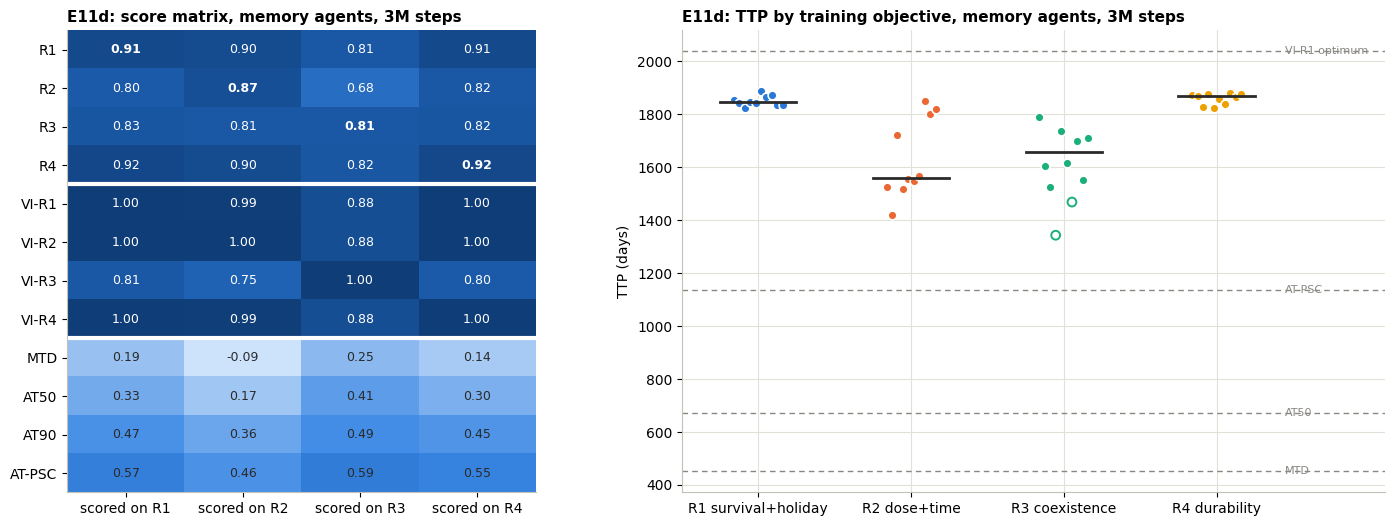

Cost of the wrong objective (memory agents, 3M):


,R1,R2,R3,R4
R1,0.000,-0.024,0.001,0.010
R2,0.118,0.000,0.133,0.107
R3,0.088,0.060,0.000,0.101
R4,-0.010,-0.024,-0.005,0.000


,median_a,median_b,diff,mannwhitney_p
pair,,,,
R1 vs R2,1844.775,1560.019,284.756,1.008e-03
R1 vs R3,1844.775,1657.896,186.879,4.571e-05
R1 vs R4,1844.775,1867.899,-23.124,3.447e-01
R2 vs R3,1560.019,1657.896,-97.877,6.965e-01
R2 vs R4,1560.019,1867.899,-307.881,4.396e-04
R3 vs R4,1657.896,1867.899,-210.004,4.571e-05


Largest wrong-objective cost by setting: {'full state': 0.176, 'burden + critic': 0.035, 'history 1M': 0.105, 'history 3M': 0.133}


In [43]:
ENOUGHd = okd.obj.value_counts().ge(2).sum() >= 2
if not ENOUGHd:
    print('Skipped: too few 3M memory agents trained.')
else:
    Md, LOSSd = score_matrix(okd, e1, e2, FLOOR, CEIL, ['MTD', 'AT50', BEST_AT, 'AT-PSC'])
    Md.to_csv(f'{RES}/E11d_score_matrix.csv')
    okd.groupby('obj')[cols].agg(miqr).to_csv(f'{RES}/E11d_cross_evaluation.csv')
    kwd, pairsd, icd = ttp_tests(okd)
    fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw=dict(width_ratios=[1, 1.5], wspace=.25))
    plot_score_matrix(axs[0], Md, 'E11d: score matrix, memory agents, 3M steps')
    plot_ttp(axs[1], evd, e1, e2, BEST_H, 'E11d: TTP by training objective, memory agents, 3M steps')
    save('E11d_cross_evaluation')
    SUMMARY['E11d_cross'] = dict(TTP_median={o: round(float(okd[okd.obj == o].TTP.median())) for o in OBJECTIVES},
                                 kruskal_p=float(kwd.pvalue), instrumental_convergence_p=float(icd.pvalue),
                                 score_matrix=Md.loc[list(OBJECTIVES)].round(3).to_dict(), loss=LOSSd.round(3).to_dict())
    print('Cost of the wrong objective (memory agents, 3M):'); display(LOSSd.round(3))
    display(pairsd)
    print('Largest wrong-objective cost by setting:',
          {k: round(float(L.values.max()), 3) for k, L in (('full state', LOSS), ('burden + critic', LOSSa),
                                                            ('history 1M', LOSSm), ('history 3M', LOSSd))})

shared history set: 14014 distinct 8-week charts


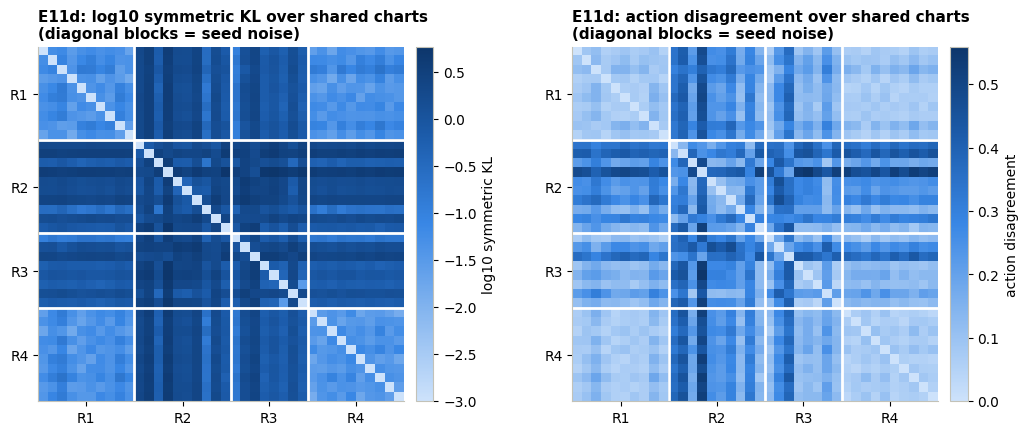

,between_KL,within_KL,ratio,p_KL,between_disagree,within_disagree,p_disagree,verdict
pair,,,,,,,,
R1 vs R2,1.720,1.019,1.688,5.999e-04,0.286,0.177,5.999e-04,DIFFERENT policies
R1 vs R3,0.976,0.653,1.494,2.000e-04,0.182,0.141,7.998e-04,DIFFERENT policies
R1 vs R4,0.058,0.050,1.166,2.819e-02,0.086,0.080,5.859e-02,not distinguishable from seed noise
R2 vs R3,2.252,1.837,1.225,2.220e-02,0.302,0.248,1.100e-02,not distinguishable from seed noise
R2 vs R4,1.740,1.010,1.723,7.998e-04,0.279,0.167,5.999e-04,DIFFERENT policies
R3 vs R4,0.989,0.642,1.541,2.000e-04,0.181,0.129,2.000e-04,DIFFERENT policies


between-objective disagreement as a multiple of seed noise, by setting:


,full state,burden + critic,history 1M,history 3M
pair,,,,
R1 vs R2,2.75,3.27,2.01,1.61
R1 vs R3,3.78,4.23,1.39,1.29
R1 vs R4,1.10,1.03,1.05,1.07
R2 vs R3,4.84,1.51,1.41,1.22
R2 vs R4,2.12,1.84,1.49,1.67
R3 vs R4,3.71,2.54,1.22,1.41


within-objective (seed-noise) disagreement, mean over pairs: {'full state': 0.058, 'burden + critic': 0.037, 'history 1M': 0.152, 'history 3M': 0.157}


In [44]:
if not ENOUGHd:
    print('Skipped (see above).')
else:
    trajs_d = [rollout(a, [POP], record=True, objs=())['traj'] for a in list(AGd.values()) + list(AGa.values()) + list(BASE.values())]
    PSd = history_space(AGd, okd, trajs_d)
    plot_history_divergence(PSd, 'E11d'); save('E11d_policy_divergence')
    SUMMARY['E11d_divergence'] = PSd['div'][['between_KL', 'within_KL', 'p_KL', 'between_disagree', 'within_disagree', 'verdict']].round(4).to_dict('index')
    display(PSd['div'])
    ratio = lambda ps: ps['div'].between_disagree / ps['div'].within_disagree
    print('between-objective disagreement as a multiple of seed noise, by setting:')
    display(pd.DataFrame({'full state': ratio(PS), 'burden + critic': ratio(PSa), 'history 1M': ratio(PSm), 'history 3M': ratio(PSd)}).round(2))
    print('within-objective (seed-noise) disagreement, mean over pairs:',
          {k: round(float(p['div'].within_disagree.mean()), 3) for k, p in (('full state', PS), ('burden + critic', PSa), ('history 1M', PSm), ('history 3M', PSd))})

**Reading E11d.** Tripling the budget closes the learning gap, and the objective effect does *not* go away.
- **Learning catches up.** Scores rise to R1 0.92 / R2 0.87 / R3 0.80 / R4 0.92, the same as the memoryless E11b agents, and 8 of 10 R3 seeds now train (6 at 1M). The learning curves are near a plateau by 3M steps.
- **The objective effect is stable, so it is not a training artefact of E11c.** The R1–R3 gap is 235 d (220 at 1M). The ordering R1 ≈ R4 > R3 > R2 is set by about 0.5M steps and never changes. The largest wrong-objective cost is 0.133 (0.105 at 1M; full state 0.176).
- **R2's dose-sparing policy persists.** It uses 21% less drug (1050 vs 1326 d) and progresses 15% sooner (1560 d). R1-trained agents still score *higher on R2's own objective* (by 0.024). More training does not move R2 to its own optimum, which VI shows is containment. With memory, PPO reliably settles into this local optimum of R2's flat objective.
- **R3's early-treatment signature partly returns.** R3 spends 0.58 of the first 26 weeks on drug, against 0.54 for every other objective (full state: 0.62 vs 0.58). But R3-trained agents still do no better than R1-trained ones *on R3's own objective* (0.803 vs 0.802).
- **Seed noise does not shrink with budget.** Within-objective disagreement over shared charts is 0.157, against 0.152 at 1M and 0.037 for memoryless agents. Many different 16-input policies earn nearly the same return. Between-objective differences are 1.1–1.7× seed noise. 4 of 6 pairs differ: R1 ≡ R4 as always, and R2 vs R3 is now indistinguishable.

**Bottom line:** with a clinically realistic chart and enough training, the objectives *do* lead to different outcomes. TTP orders R1 ≈ R4 > R3 > R2, and the cost of the wrong objective (0.13) is close to the full-state value (0.18). But for R2 and R3 the difference is not a better way of serving their own objective. It is which local optimum each objective's reward landscape leads PPO into, because the agents trained on R2 and R3 score no better on R2 and R3 than agents trained on survival.

## Findings

1. **Does the objective change the policy?** **Yes, but mostly through one objective.** At the optimum, survival (R1), dose+time (R2) and durability (R4) all converge on containment just below the progression line. Coexistence (R3) is the outlier: it front-loads treatment and progresses about 250–400 days earlier. In policy space, five of six pairs differ beyond seed noise. R1 ≡ R4 holds for both durability definitions (resistant-population regrowth and resistant fraction after a holiday), on both patients. A larger durability weight changes the policy only by making the agent give up early, and closing that loophole restores containment (E3c).
2. **Cost of the wrong objective.** Optimising coexistence costs 12–18% of the achievable optimum on every other objective. Optimising survival costs ≤ 2% elsewhere, and scores slightly *better* on coexistence than coexistence training itself.
3. **Instrumental convergence.** It fails as hypothesised and holds in reverse: survival is instrumentally useful for coexistence, not the other way round.
4. **Why coexistence underperforms.** Below Strobl's controllability bound, a two-population resistant fraction cannot be held at any target (E6b). The entropy reward then reduces to its boundary and progression penalties.
5. **What survives robustness checks.** R3-last survives a held-out cohort, ±25% parameter perturbation, a 28-day cadence, two drug-mechanism changes, and a patient with a cost of resistance (E3c). The order among R1, R2 and R4 does not, and is not a finding.
6. **RL vs the optimum.** The exact optimum is about 15% better on the nominal patient but brittle under misspecification, while the agents' safety margin keeps them robust. Every learned policy fails if monitored less often than it was trained for.
7. **Burden-only observation.** Memoryless PPO agents that see only tumour burden fail to train (0.21–0.37 of the optimum) even though a one-line burden threshold rule reaches 0.96. With a clinically realistic observation, the bottleneck is learning, not information (E11). Giving the critic the full state during training fixes it (item 8).

8. **Observation matters more than objective.** With a burden-only actor trained through a full-state critic, every objective's agents beat the full-state agents (0.80–0.92 of the optimum, all 40 trained). The four objectives also nearly converge: the R1–R3 gap is 76 d instead of 250 d, and the wrong-objective cost is ≤ 0.035 instead of 0.12–0.18. R3 is still last, but by about 4%. Most of the objective effect depends on composition information a clinician does not have (E11b).

9. **Memory.** With an 8-week burden chart, the objective effect partly returns: the R1–R3 gap is 220 d and the wrong-objective cost reaches 0.105. But it is noisier and driven by learning. R3's front-loaded treatment does not return. R2 becomes the outlier only because its flat objective lets harder learning settle on a dose-sparing policy that is no better for R2 (E11c). Across all four observation settings, the robust results are R1 ≡ R4, R3 never beating R1, and a cost of the wrong objective that depends on what the agent can observe.

10. **More training does not erase the effect, and does not justify it either.** At 3× budget the memory agents learn as well as the memoryless ones (0.80–0.92). The R1–R3 gap (235 d) and the wrong-objective cost (0.13) persist. But R2- and R3-trained agents still score no better on their *own* objectives than survival-trained agents. Their divergence reflects the local optima their reward landscapes lead PPO into, not better service of what they reward (E11d).

All numbers are from `results/summary.json`. Limitations and design choices are in `README.md` and `decisions.md`.

## Summary

All key numbers are collected in `results/summary.json`, and that file is what the README quotes.

In [45]:
with open(f'{RES}/summary.json', 'w') as f:
    json.dump(SUMMARY, f, indent=1, default=float)
print(json.dumps(SUMMARY, indent=1, default=float)[:6000])

{
 "E0": {
  "CT": 451.6,
  "AT50_daily": 662.8,
  "AT50_weekly": 673.2,
  "AT50_28d_checked_at_decisions": 672.0
 },
 "E1": {
  "None": 40.7,
  "MTD": 451.6,
  "AT25": 587.6,
  "AT50": 673.2,
  "AT75": 798.1,
  "AT90": 932.5,
  "IT": 166.5,
  "AT-PSC": 1135.0
 },
 "E1_heatmap": {
  "gain_range": [
   2.05,
   3.29
  ],
  "headroom_range": [
   2.19,
   6.45
  ]
 },
 "E2": {
  "R1": {
   "TTP": 2038,
   "G": 28.85,
   "dose_pct": 71.8
  },
  "R2": {
   "TTP": 2030,
   "G": -93.6,
   "dose_pct": 71.4
  },
  "R3": {
   "TTP": 1625,
   "G": -80.6,
   "dose_pct": 73.2
  },
  "R4": {
   "TTP": 2038,
   "G": 23.49,
   "dose_pct": 71.8
  }
 },
 "E3": {
  "R1": {
   "median_score": 0.867,
   "min_score": 0.837,
   "trained": 10
  },
  "R2": {
   "median_score": 0.848,
   "min_score": 0.824,
   "trained": 10
  },
  "R3": {
   "median_score": 0.763,
   "min_score": 0.732,
   "trained": 10
  },
  "R4": {
   "median_score": 0.868,
   "min_score": 0.842,
   "trained": 10
  }
 },
 "E4": {
  "TTP_med